In [1]:
RECOMPUTE_FULL = False


In [2]:
import numpy as np
import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from scipy.signal import welch, spectrogram as sp_spectrogram
from scipy.signal import hilbert, butter, filtfilt
from scipy.special import erf as sc_erf
from scipy.optimize import curve_fit
import math, os, time, pickle

BASE   = "data"
FIGDIR = os.path.join("figures_gamma", "02")
os.makedirs(FIGDIR, exist_ok=True)

In [3]:
##generate a noise
def ornstein_uhlenbeck(mu, sigma, theta, dt, T, x0):
    num_steps = int(T / dt)
    t = np.linspace(0, T, num_steps + 1)
    x = np.zeros(num_steps + 1)
    x[0] = x0
    for i in range(1, num_steps + 1):
        dW = np.random.normal(0, np.sqrt(dt))
        x[i] = x[i - 1] + theta * (mu - x[i - 1]) * dt + sigma * dW
    return t, x

mu = 0.
sigma = 10
theta = 200
dt = 0.0001
T_duration = 4
x0 = 0.0

tf, xf = ornstein_uhlenbeck(mu, sigma, theta, dt, T_duration, x0)
xf = xf[:-1]

In [4]:
# Chargement des fonctions de transfert
PRS = np.load(os.path.join(BASE, "RS-cell_CONFIG1_fit.npy"))[[0,1,2,3,5,8,9,6,10,7]]
PFS = np.load(os.path.join(BASE, "FS-cell_CONFIG1_fit.npy"))[[0,1,2,3,5,8,9,6,10,7]]

# Parametres neuronaux 
Gl=10e-9; Cm=200e-12; El=-65e-3; Ee=0.; Ei=-80e-3
bRS=60e-12; a=4e-9; twRS=0.5
Qe=1.25e-9; Qi=5e-9; Ti=5e-3; Te=5e-3; tau_l=0.003

# Parametres reseau
pconnec=0.05; gei=0.2; Ntot=10000
T=0.005; epsilon=0.05
input_to_exc=4.; input_to_inh=4.

def TF(P, fexc, finh, adapt, El_):
    fe=fexc*(1.-gei)*pconnec*Ntot; fi=finh*gei*pconnec*Ntot
    muGi=Qi*Ti*fi; muGe=Qe*Te*fe; muG=Gl+muGe+muGi
    muV=(muGe*Ee+muGi*Ei+Gl*El_-adapt)/muG; Tm=Cm/muG
    Ue=Qe/muG*(Ee-muV); Ui=Qi/muG*(Ei-muV)
    sV2=fe*(Ue*Te)**2/2./(Te+Tm)+fi*(Ui*Ti)**2/2./(Ti+Tm)
    sV=math.sqrt(max(sV2,0.))+1e-12
    fe+=1e-9; fi+=1e-9
    num=fe*(Ue*Te)**2+fi*(Ui*Ti)**2
    den=fe*(Ue*Te)**2/(Te+Tm)+fi*(Ui*Ti)**2/(Ti+Tm)  
    TvN=max((num/den if den>1e-20 else 0.5)*Gl/Cm, 1e-6)
    mu0=-60e-3; Dmu=10e-3; s0=4e-3; Ds=6e-3; Tv0=0.5; DTv=1.
    vthr=(P[0]+P[1]*(muV-mu0)/Dmu+P[2]*(sV-s0)/Ds+P[3]*(TvN-Tv0)/DTv
         +P[4]*((muV-mu0)/Dmu)**2+P[5]*(muV-mu0)/Dmu*(sV-s0)/Ds
         +P[6]*(muV-mu0)/Dmu*(TvN-Tv0)/DTv+P[7]*((sV-s0)/Ds)**2
         +P[8]*(sV-s0)/Ds*(TvN-Tv0)/DTv+P[9]*((TvN-Tv0)/DTv)**2)
    return float(max(0.5/TvN*Gl/Cm*(1.-sc_erf((vthr-muV)/(math.sqrt(2.)*sV))), 1e-9))

def MFw(fexc, finh, adapt, ff, El_):
    fe=fexc*(1.-gei)*pconnec*Ntot; fi=finh*gei*pconnec*Ntot
    muGi=Qi*Ti*fi; muGe=Qe*Te*fe; muG=Gl+muGe+muGi
    muV=(muGe*Ee+muGi*Ei+Gl*El_-adapt)/muG
    return -adapt/twRS+bRS*ff+a*(muV-El_)/twRS


Low gamma  Ele=-68mV  Eli=-58mV ...


High gamma  Ele=-58mV  Eli=-72mV ...


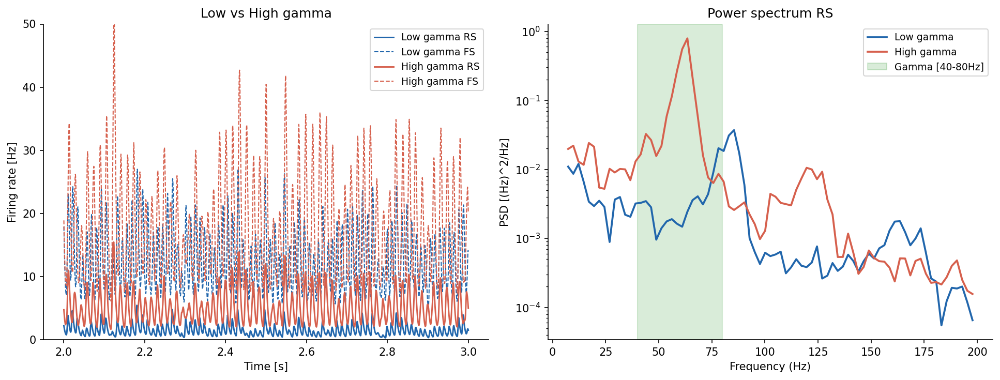

In [5]:
STATES = {
    "Low gamma" : dict(Ele=-68e-3, Eli=-58e-3, color="#2166AC"),
    "High gamma": dict(Ele=-58e-3, Eli=-72e-3, color="#D6604D"),
}

tfinal=4; tsteps=int(tfinal/dt); t=np.linspace(0,tfinal,tsteps)

traces={}
for label,cfg in STATES.items():
    Ele=cfg["Ele"]; Eli=cfg["Eli"]
    print(f"{label}  Ele={Ele*1e3:.0f}mV  Eli={Eli*1e3:.0f}mV ...",flush=True)
    w=1e-10; fecont=1.; ficont=1.
    LSw=[w]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSfe=[fecont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt))); LSfi=[ficont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    tau_e_d=int((1+epsilon)*tau_l/dt); tau_i_d=int((1-epsilon)*tau_l/dt)
    for i in range(max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)),len(t)):
        fecont+=dt/T*(TF(PRS,LSfe[i-tau_e_d]+xf[i]+input_to_exc,LSfi[i-tau_i_d],LSw[i],Ele)-LSfe[i])
        ficont+=dt/T*(TF(PFS,LSfe[i-tau_i_d]+xf[i]+input_to_inh,LSfi[i-tau_e_d],0.,Eli)-LSfi[i])
        w+=dt*MFw(LSfe[i],LSfi[i],LSw[i],LSfe[i],Ele)
        fecont=min(max(fecont,1e-9),196); ficont=min(max(ficont,1e-9),196)
        LSfe.append(float(fecont)); LSfi.append(float(ficont)); LSw.append(float(w))
    LSfe.pop(0); LSfi.pop(0); LSw.pop(0)
    traces[label]=dict(LSfe=LSfe,LSfi=LSfi,LSw=LSw,**cfg)
    sl=slice(int(2/dt),int(3/dt))

# Figure firing rate
sl=slice(int(2/dt),int(3/dt)); t_sl=t[sl]
fig,axes=plt.subplots(1,2,figsize=(13,5),dpi=150)
fig.patch.set_facecolor("white")
for label,d in traces.items():
    fe=np.array(d["LSfe"])[sl]; fi=np.array(d["LSfi"])[sl]; col=d["color"]
    axes[0].plot(t_sl,fe,color=col,lw=1.4,label=f"{label} RS")
    axes[0].plot(t_sl,fi,color=col,lw=1.0,ls='--',label=f"{label} FS")
axes[0].set_xlabel("Time [s]"); axes[0].set_ylabel("Firing rate [Hz]")
axes[0].set_title("Low vs High gamma"); axes[0].legend(fontsize=9)
axes[0].set_ylim(0,50); axes[0].spines[['top','right']].set_visible(False)

# PSD
half=len(t)//2
for label,d in traces.items():
    sig=np.array(d["LSfe"])[half:]-np.mean(np.array(d["LSfe"])[half:])
    freqs,psd=welch(sig,fs=int(1/dt),nperseg=4096)
    mask=(freqs>5)&(freqs<200)
    axes[1].semilogy(freqs[mask],psd[mask],color=d["color"],lw=1.8,label=label)
axes[1].axvspan(40,80,alpha=0.15,color='green',label='Gamma [40-80Hz]')
axes[1].set_xlabel("Frequency (Hz)"); axes[1].set_ylabel("PSD [(Hz)^2/Hz]")
axes[1].set_title("Power spectrum RS"); axes[1].legend(fontsize=9)
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
fpath=os.path.join(FIGDIR,"FIG_firing_rate_v4.png")
fig.savefig(fpath,dpi=150,bbox_inches='tight',facecolor='white')

In [6]:
SIGMAS=[5,10,30,60]; AMP=0.9; SEED=42; N_STIM=200; SPACING=1.2
T_TOTAL=N_STIM*SPACING+2.0; N_STEPS=int(T_TOTAL/dt)
t_sta=np.arange(N_STEPS)*dt
T_STIM=1.0+np.arange(N_STIM)*SPACING
W_PRE=0.200; W_POST=0.600
N_PRE=int(W_PRE/dt); N_POST=int(W_POST/dt); N_WIN=N_PRE+N_POST
t_win=np.arange(-N_PRE,N_POST)*dt*1000  # ms
pre_sl=(t_win>=-200)&(t_win<-50)
ep_sl=(t_win>=0)&(t_win<=200)

=== G per-trial (mean amp High / mean amp Low) + t-test 
  sigma= 5ms  G_fe=0.872 OK (t=-0.83 p=0.405 ns)  G_fi=1.509 !! (t=+2.61 p=0.0095 **)  G_fc=0.948 OK (t=-0.33 p=0.739 ns)  


  sigma=10ms  G_fe=0.653 OK (t=-2.53 p=0.0119 *)  G_fi=1.329 !! (t=+1.72 p=0.087 ns)  G_fc=0.732 OK (t=-1.88 p=0.0613 ns)  
  sigma=30ms  G_fe=0.553 OK (t=-3.42 p=0.000712 ***)  G_fi=1.177 !! (t=+0.99 p=0.323 ns)  G_fc=0.624 OK (t=-2.79 p=0.00555 **)  


  sigma=60ms  G_fe=0.552 OK (t=-2.93 p=0.00355 **)  G_fi=1.151 !! (t=+0.75 p=0.457 ns)  G_fc=0.621 OK (t=-2.42 p=0.0158 *)  


C:\Users\fayre\AppData\Local\Temp\ipykernel_14764\3732869623.py:159: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,1,0.97])


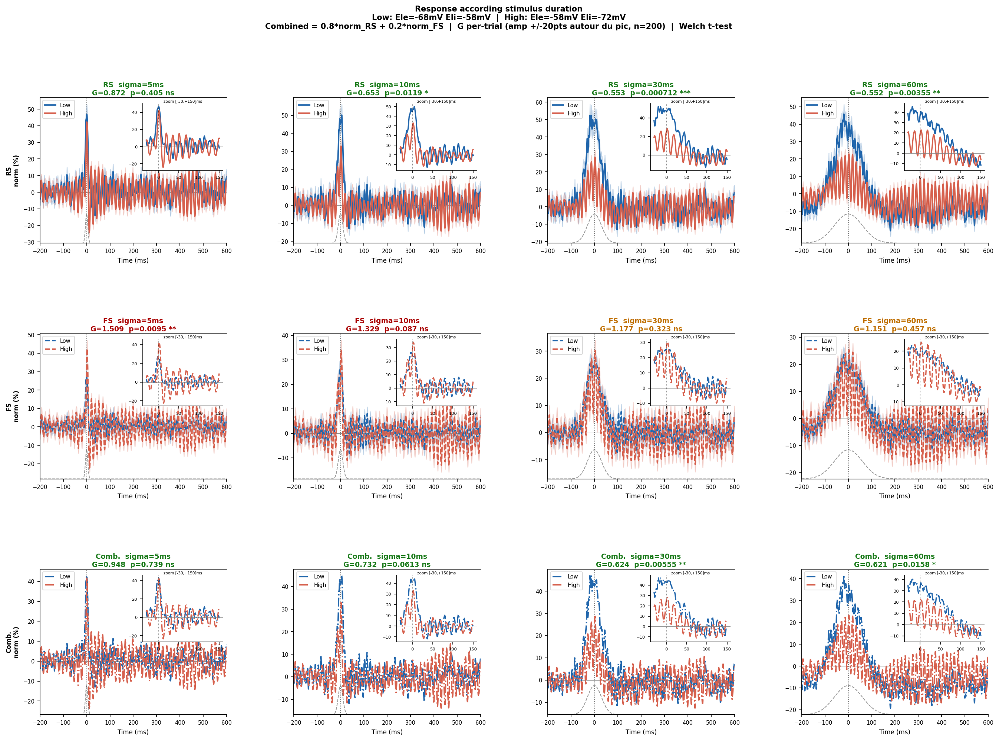

In [7]:
def run_sta_full(Ele, Eli, sig_ms, seed=SEED):
    imp=np.zeros(N_STEPS)
    for ts in T_STIM:
        imp+=AMP*np.exp(-0.5*((t_sta-ts)/(sig_ms*1e-3))**2)
    np.random.seed(seed)
    _, xf_s = ornstein_uhlenbeck(mu,sigma,theta,dt,T_TOTAL,x0); xf_s=xf_s[:-1]
    w=1e-10; fecont=1.; ficont=1.
    LSfe_s=[fecont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSfi_s=[ficont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSw_s=[w]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    fe_out=np.zeros(N_STEPS); fi_out=np.zeros(N_STEPS)
    tau_e_d=int((1+epsilon)*tau_l/dt); tau_i_d=int((1-epsilon)*tau_l/dt)
    for i in range(max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)),N_STEPS):
        inp=xf_s[i]+input_to_exc+imp[i]
        fecont+=dt/T*(TF(PRS,LSfe_s[i-tau_e_d]+inp,LSfi_s[i-tau_i_d],LSw_s[i],Ele)-LSfe_s[i])
        ficont+=dt/T*(TF(PFS,LSfe_s[i-tau_i_d]+inp,LSfi_s[i-tau_e_d],0.,Eli)-LSfi_s[i])
        w+=dt*MFw(LSfe_s[i],LSfi_s[i],LSw_s[i],LSfe_s[i],Ele)
        fecont=min(max(fecont,1e-9),196); ficont=min(max(ficont,1e-9),196)
        LSfe_s.append(float(fecont)); LSfi_s.append(float(ficont)); LSw_s.append(float(w))
        fe_out[i]=fecont; fi_out[i]=ficont
    def extract(sig):
        wins=[sig[int(round(ts/dt))-N_PRE:int(round(ts/dt))+N_POST]
              for ts in T_STIM if int(round(ts/dt))-N_PRE>=0 and int(round(ts/dt))+N_POST<=N_STEPS]
        wins=np.array(wins)
        return wins.mean(axis=0),wins.std(axis=0,ddof=1)/np.sqrt(len(wins)),wins
    sta_fe_m,sta_fe_s,wins_fe=extract(fe_out); sta_fi_m,sta_fi_s,wins_fi=extract(fi_out)
    b_fe=float(sta_fe_m[pre_sl].mean()); b_fi=float(sta_fi_m[pre_sl].mean())
    ep_fe=float(sta_fe_m[ep_sl].max())-b_fe; ep_fi=float(sta_fi_m[ep_sl].max())-b_fi
    return dict(sta_fe=sta_fe_m,sem_fe=sta_fe_s,base_fe=b_fe,ep_fe=ep_fe,
                sta_fi=sta_fi_m,sem_fi=sta_fi_s,base_fi=b_fi,ep_fi=ep_fi,
                trials_fe=wins_fe,trials_fi=wins_fi,n_trials=len(wins_fe))

CACHE_V5=os.path.join(BASE,"sta_results_v5_trials.pkl")
t0=time.time(); results={}
if os.path.exists(CACHE_V5):
    with open(CACHE_V5,"rb") as f: results=pickle.load(f)
else:
    for sname,cfg in STATES.items():
        results[sname]={}
        for sig in SIGMAS:
            print(f"  {sname} sigma={sig}ms ...",flush=True)
            results[sname][sig]=run_sta_full(cfg["Ele"],cfg["Eli"],sig)
    with open(CACHE_V5,"wb") as f: pickle.dump(results,f)

_n=len(results[list(results.keys())[0]][SIGMAS[0]]["sta_fe"])
if _n!=N_WIN:
    t_win=np.arange(-N_PRE,_n-N_PRE)*dt*1000
    pre_sl=(t_win>=-200)&(t_win<-50)
    ep_sl=(t_win>=0)&(t_win<=200)
    print(f"t_win adapte: {len(t_win)} pts")



from scipy.stats import ttest_ind

C_LOW="#2166AC"; C_HIGH="#D6604D"
lat_sl=(t_win>=0)&(t_win<=150)
HW=20

def p_stars(p):
    if np.isnan(p): return "n/a"
    return "***" if p<0.001 else "**" if p<0.01 else "*" if p<0.05 else "ns"

def amp_pertrial(wins):
    m=wins.mean(axis=0); idx=np.where(lat_sl)[0]
    it=int(idx[np.argmax(m[lat_sl])])
    lo=max(0,it-HW); hi=min(wins.shape[1],it+HW+1)
    return wins[:,lo:hi].mean(axis=1)-wins[:,pre_sl].mean(axis=1), float(t_win[it])

def welch_p(a,b):
    a=np.asarray(a,float); b=np.asarray(b,float)
    if a.size<3 or b.size<3: return float("nan"), float("nan")
    t,p=ttest_ind(a,b,equal_var=False); return float(t),float(p)

def amp_norm_pt(d, pop):
    a,lat=amp_pertrial(np.asarray(d[f"trials_{pop}"]))
    return a/max(abs(d[f"base_{pop}"]),1e-9)*100, lat

def amp_norm_pt_comb(d, we=0.8, wi=0.2):
    tre=(np.asarray(d["trials_fe"])-d["base_fe"])/max(abs(d["base_fe"]),1e-9)*100
    tri=(np.asarray(d["trials_fi"])-d["base_fi"])/max(abs(d["base_fi"]),1e-9)*100
    a,lat=amp_pertrial(we*tre+wi*tri)
    return a,lat

G_rel={}
print("=== G per-trial (mean amp High / mean amp Low) + t-test ")
for sig in SIGMAS:
    hi=results["High gamma"][sig]; lo=results["Low gamma"][sig]
    a_fe_lo,lat_fe_lo=amp_norm_pt(lo,"fe"); a_fe_hi,lat_fe_hi=amp_norm_pt(hi,"fe")
    a_fi_lo,_=amp_norm_pt(lo,"fi");         a_fi_hi,_=amp_norm_pt(hi,"fi")
    a_fc_lo,_=amp_norm_pt_comb(lo);         a_fc_hi,_=amp_norm_pt_comb(hi)
    G_fe=a_fe_hi.mean()/max(a_fe_lo.mean(),1e-9)
    G_fi=a_fi_hi.mean()/max(a_fi_lo.mean(),1e-9)
    G_fc=a_fc_hi.mean()/max(a_fc_lo.mean(),1e-9)
    t_fe,p_fe=welch_p(a_fe_hi,a_fe_lo)
    t_fi,p_fi=welch_p(a_fi_hi,a_fi_lo)
    t_fc,p_fc=welch_p(a_fc_hi,a_fc_lo)
    G_rel[sig]=dict(G_fe=G_fe,G_fi=G_fi,G_fc=G_fc,
                    p_fe=p_fe,p_fi=p_fi,p_fc=p_fc,
                    lat_lo=lat_fe_lo,lat_hi=lat_fe_hi)
    print(f"  sigma={sig:2d}ms  "
          f"G_fe={G_fe:.3f} {'OK' if G_fe<1 else '!!'} (t={t_fe:+.2f} p={p_fe:.3g} {p_stars(p_fe)})  "
          f"G_fi={G_fi:.3f} {'OK' if G_fi<1 else '!!'} (t={t_fi:+.2f} p={p_fi:.3g} {p_stars(p_fi)})  "
          f"G_fc={G_fc:.3f} {'OK' if G_fc<1 else '!!'} (t={t_fc:+.2f} p={p_fc:.3g} {p_stars(p_fc)})  ")


def norm_pct(arr,base):
    return (arr-base)/max(abs(base),1e-9)*100

fig=plt.figure(figsize=(5.5*len(SIGMAS),4.8*3),dpi=150)
fig.patch.set_facecolor("white")
gs=gridspec.GridSpec(3,len(SIGMAS),figure=fig,hspace=0.62,wspace=0.36)

for col,sig in enumerate(SIGMAS):
    imp_disp=AMP*np.exp(-0.5*(t_win/sig)**2)
    d=G_rel[sig]
    hi=results["High gamma"][sig]; lo=results["Low gamma"][sig]
    nfe_lo=norm_pct(np.asarray(lo["sta_fe"]),lo["base_fe"])
    nfi_lo=norm_pct(np.asarray(lo["sta_fi"]),lo["base_fi"])
    nfe_hi=norm_pct(np.asarray(hi["sta_fe"]),hi["base_fe"])
    nfi_hi=norm_pct(np.asarray(hi["sta_fi"]),hi["base_fi"])
    nfc_lo=0.8*nfe_lo+0.2*nfi_lo; nfc_hi=0.8*nfe_hi+0.2*nfi_hi
    row_data=[
        ("RS",   nfe_lo,nfe_hi,d["G_fe"],d["p_fe"],"-",  "sem_fe","base_fe"),
        ("FS",   nfi_lo,nfi_hi,d["G_fi"],d["p_fi"],"--", "sem_fi","base_fi"),
        ("Comb.",nfc_lo,nfc_hi,d["G_fc"],d["p_fc"],"-.",None,None),
    ]
    for row,(pop,m_lo,m_hi,G,pval,ls,sem_k,base_k) in enumerate(row_data):
        ax=fig.add_subplot(gs[row,col])
        gcol="#1a7a1a" if G<1 else ("#c07000" if G<1.3 else "#aa0000")
        ax.plot(t_win,m_lo,color=C_LOW,lw=1.8,ls=ls,label="Low",zorder=3)
        ax.plot(t_win,m_hi,color=C_HIGH,lw=1.8,ls=ls,label="High",zorder=3)
        if sem_k:
            s_lo=np.asarray(lo[sem_k])/max(abs(lo[base_k]),1e-9)*100
            s_hi=np.asarray(hi[sem_k])/max(abs(hi[base_k]),1e-9)*100
            ax.fill_between(t_win,m_lo-s_lo,m_lo+s_lo,color=C_LOW,alpha=0.18,zorder=2)
            ax.fill_between(t_win,m_hi-s_hi,m_hi+s_hi,color=C_HIGH,alpha=0.18,zorder=2)
        axt=ax.twinx(); axt.plot(t_win,imp_disp,"k--",lw=1.0,alpha=0.4)
        axt.set_ylim(0,AMP*5); axt.set_yticks([]); axt.spines["right"].set_visible(False)
        ax.axvline(0,color="k",ls=":",lw=0.9,alpha=0.55); ax.axhline(0,color="gray",lw=0.5)
        ax.set_xlim(-200,600); ax.set_xlabel("Time (ms)",fontsize=8)
        ax.tick_params(labelsize=7); ax.spines[["top","right"]].set_visible(False)
        ax.legend(fontsize=7,loc="upper left",framealpha=0.7)
        ax.set_title(f"{pop}  sigma={sig}ms\nG={G:.3f}  p={pval:.3g} {p_stars(pval)}",
                     fontsize=9,fontweight="bold",color=gcol,pad=3)
        if col==0: ax.set_ylabel(f"{pop}\nnorm (%)",fontsize=8,fontweight="bold")
        axins=ax.inset_axes([0.55,0.50,0.43,0.46])
        zsl=(t_win>=-30)&(t_win<=150)
        axins.plot(t_win[zsl],m_lo[zsl],color=C_LOW,lw=1.6,ls=ls)
        axins.plot(t_win[zsl],m_hi[zsl],color=C_HIGH,lw=1.6,ls=ls)
        axins.axvline(0,color="k",ls=":",lw=0.7,alpha=0.5); axins.axhline(0,color="gray",lw=0.4)
        axins.tick_params(labelsize=5.5); axins.set_title("zoom [-30,+150]ms",fontsize=5,pad=1.5)
        axins.spines[["top","right"]].set_visible(False)

fig.suptitle(f"Response according stimulus duration\n"
             "Low: Ele=-68mV Eli=-58mV  |  High: Ele=-58mV Eli=-72mV\n"
             "Combined = 0.8*norm_RS + 0.2*norm_FS  |  G per-trial (amp +/-20pts autour du pic, n=200)  |  Welch t-test",
             fontsize=10,fontweight="bold",x=0.5,y=0.995)
plt.tight_layout(rect=[0,0,1,0.97])
fpath=os.path.join(FIGDIR,"FIG_sta_v5_pertrial.png")
fig.savefig(fpath,dpi=150,bbox_inches="tight",facecolor="white")


=== Input asymetrique sigma=10ms ===
  factor=0.1x  G_fe=1.807 !!  G_fi=1.402 !!  G_fc=1.694 !!
  factor=0.2x  G_fe=1.007 !!  G_fi=1.054 !!  G_fc=1.018 !!
  factor=0.3x  G_fe=1.482 !!  G_fi=1.18 !!  G_fc=1.402 !!
  factor=0.4x  G_fe=1.062 !!  G_fi=0.887 OK  G_fc=1.009 !!
  factor=0.5x  G_fe=0.395 OK  G_fi=0.465 OK  G_fc=0.412 OK
  factor=0.6x  G_fe=0.249 OK  G_fi=0.228 OK  G_fc=0.245 OK
  factor=0.7x  G_fe=0.542 OK  G_fi=0.657 OK  G_fc=0.566 OK
  factor=0.8x  G_fe=0.365 OK  G_fi=0.57 OK  G_fc=0.404 OK
  factor=0.9x  G_fe=0.527 OK  G_fi=0.969 OK  G_fc=0.586 OK
  factor=1.0x  G_fe=0.655 OK  G_fi=1.374 !!  G_fc=0.734 OK
  factor=1.1x  G_fe=0.399 OK  G_fi=1.002 !!  G_fc=0.454 OK
  factor=1.2x  G_fe=0.505 OK  G_fi=1.485 !!  G_fc=0.575 OK
  factor=1.3x  G_fe=0.438 OK  G_fi=1.495 !!  G_fc=0.495 OK
  factor=1.4x  G_fe=0.46 OK  G_fi=1.272 !!  G_fc=0.499 OK
  factor=1.5x  G_fe=0.451 OK  G_fi=1.479 !!  G_fc=0.489 OK
  factor=1.6x  G_fe=0.398 OK  G_fi=1.437 !!  G_fc=0.426 OK
  factor=1.7x  G_fe=0.

Figure: figures_gamma\02\FIG_asym_v4.png





In [8]:
ASYM_FACTORS=[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2]; SIGMA_ASYM=10
N_STIM_A=200; SPACING_A=1.2; T_TOTAL_A=N_STIM_A*SPACING_A+2.0
N_STEPS_A=int(T_TOTAL_A/dt); t_sta_A=np.arange(N_STEPS_A)*dt
T_STIM_A=1.0+np.arange(N_STIM_A)*SPACING_A
pre_sl_A=(np.arange(-N_PRE,N_POST)*dt*1000>=-200)&(np.arange(-N_PRE,N_POST)*dt*1000<-50)
ep_sl_A=(np.arange(-N_PRE,N_POST)*dt*1000>=0)&(np.arange(-N_PRE,N_POST)*dt*1000<=200)

def run_sta_asym_inh(Ele,Eli,sig_ms,asym_factor,seed=SEED):
    imp=np.zeros(N_STEPS_A)
    for ts in T_STIM_A:
        imp+=AMP*np.exp(-0.5*((t_sta_A-ts)/(sig_ms*1e-3))**2)
    np.random.seed(seed)
    _, xf_a = ornstein_uhlenbeck(mu,sigma,theta,dt,T_TOTAL_A,x0); xf_a=xf_a[:-1]
    w=1e-10; fecont=1.; ficont=1.
    LSfe_a=[fecont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSfi_a=[ficont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSw_a=[w]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    fe_out=np.zeros(N_STEPS_A); fi_out=np.zeros(N_STEPS_A)
    inp_inh=asym_factor*input_to_exc
    tau_e_d=int((1+epsilon)*tau_l/dt); tau_i_d=int((1-epsilon)*tau_l/dt)
    for i in range(max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)),N_STEPS_A):
        ie=xf_a[i]+input_to_exc+imp[i]; ii=xf_a[i]+inp_inh+imp[i]
        fecont+=dt/T*(TF(PRS,LSfe_a[i-tau_e_d]+ie,LSfi_a[i-tau_i_d],LSw_a[i],Ele)-LSfe_a[i])
        ficont+=dt/T*(TF(PFS,LSfe_a[i-tau_i_d]+ii,LSfi_a[i-tau_e_d],0.,Eli)-LSfi_a[i])
        w+=dt*MFw(LSfe_a[i],LSfi_a[i],LSw_a[i],LSfe_a[i],Ele)
        fecont=min(max(fecont,1e-9),196); ficont=min(max(ficont,1e-9),196)
        LSfe_a.append(float(fecont)); LSfi_a.append(float(ficont)); LSw_a.append(float(w))
        fe_out[i]=fecont; fi_out[i]=ficont
    def extr(sig):
        wins=[sig[int(round(ts/dt))-N_PRE:int(round(ts/dt))+N_POST]
              for ts in T_STIM_A if int(round(ts/dt))-N_PRE>=0 and int(round(ts/dt))+N_POST<=N_STEPS_A]
        wins=np.array(wins); m=wins.mean(axis=0); s=wins.std(axis=0,ddof=1)/np.sqrt(len(wins))
        return m,s
    fe_m,fe_s=extr(fe_out); fi_m,fi_s=extr(fi_out)
    b_fe=float(fe_m[pre_sl_A].mean()); b_fi=float(fi_m[pre_sl_A].mean())
    return dict(sta_fe=fe_m,sem_fe=fe_s,base_fe=b_fe,ep_fe=float(fe_m[ep_sl_A].max())-b_fe,
                sta_fi=fi_m,sem_fi=fi_s,base_fi=b_fi,ep_fi=float(fi_m[ep_sl_A].max())-b_fi)


results_asym={}
for fac in ASYM_FACTORS:
    CACHE_A=os.path.join(BASE,'cache_asym_v4_'+str(fac)+'.pkl')
    CACHE_A=os.path.join(BASE,'cache_asym_v4_{:.1f}.pkl'.format(fac))
    if os.path.exists(CACHE_A):
        with open(CACHE_A,'rb') as f: results_asym[fac]=pickle.load(f)
    else:
        results_asym[fac]={}
        for label,cfg in STATES.items():
            print('  '+label+' factor='+str(fac)+'x ...',flush=True)
            results_asym[fac][label]=run_sta_asym_inh(cfg['Ele'],cfg['Eli'],SIGMA_ASYM,fac)
        with open(CACHE_A,'wb') as f: pickle.dump(results_asym[fac],f)

# G normalise = (ep/base_High) / (ep/base_Low)
G_asym={}
print('=== Input asymetrique sigma=' + str(SIGMA_ASYM) + 'ms ===')
for fac in ASYM_FACTORS:
    lo=results_asym[fac]['Low gamma']; hi=results_asym[fac]['High gamma']
    G_fe=(hi['ep_fe']/max(abs(hi['base_fe']),1e-9))/(lo['ep_fe']/max(abs(lo['base_fe']),1e-9))
    G_fi=(hi['ep_fi']/max(abs(hi['base_fi']),1e-9))/(lo['ep_fi']/max(abs(lo['base_fi']),1e-9))
    ep_fc_lo=0.8*(lo['ep_fe']/max(abs(lo['base_fe']),1e-9))+0.2*(lo['ep_fi']/max(abs(lo['base_fi']),1e-9))
    ep_fc_hi=0.8*(hi['ep_fe']/max(abs(hi['base_fe']),1e-9))+0.2*(hi['ep_fi']/max(abs(hi['base_fi']),1e-9))
    G_fc=ep_fc_hi/max(ep_fc_lo,1e-9)
    G_asym[fac]=dict(G_fe=G_fe,G_fi=G_fi,G_fc=G_fc)
    sfe='OK' if G_fe<1 else '!!'
    sfi='OK' if G_fi<1 else '!!'
    sfc='OK' if G_fc<1 else '!!'
    print('  factor='+str(fac)+'x  G_fe='+str(round(G_fe,3))+' '+sfe+'  G_fi='+str(round(G_fi,3))+' '+sfi+'  G_fc='+str(round(G_fc,3))+' '+sfc)

C_LOW='#2166AC'; C_HIGH='#D6604D'
fig,axes=plt.subplots(3,len(ASYM_FACTORS),figsize=(5*len(ASYM_FACTORS),10),dpi=150)
fig.patch.set_facecolor('white')
row_cfg=[('RS','sta_fe','sem_fe','base_fe'),('FS','sta_fi','sem_fi','base_fi')]
for col,fac in enumerate(ASYM_FACTORS):
    G_fc=G_asym[fac]['G_fc']; gcol='#1a7a1a' if G_fc<1 else '#aa0000'
    for row,(pop,key,sem_key,bkey) in enumerate(row_cfg):
        ax=axes[row,col]
        lo_d=results_asym[fac]['Low gamma']; hi_d=results_asym[fac]['High gamma']
        for label,d,color in [('Low',lo_d,C_LOW),('High',hi_d,C_HIGH)]:
            m=norm_pct(np.asarray(d[key]),d[bkey])
            s=np.asarray(d[sem_key])/max(abs(d[bkey]),1e-9)*100
            ax.plot(t_win,m,color=color,lw=1.8,label=label)
            ax.fill_between(t_win,m-s,m+s,color=color,alpha=0.18)
        ax.axvline(0,color='k',ls=':',lw=0.8); ax.axhline(0,color='gray',lw=0.4)
        ax.set_xlim(-100,400); ax.set_xlabel('Time (ms)',fontsize=8)
        ax.legend(fontsize=7); ax.spines[['top','right']].set_visible(False)
        if row==0: ax.set_title('factor='+str(fac)+'x  G_fc='+str(round(G_fc,3)),fontsize=9,color=gcol,fontweight='bold')
        if col==0: ax.set_ylabel(pop+' norm. (%)',fontsize=9,fontweight='bold')
    ax2=axes[2,col]
    lo_d=results_asym[fac]['Low gamma']; hi_d=results_asym[fac]['High gamma']
    for label,d,color in [('Low',lo_d,C_LOW),('High',hi_d,C_HIGH)]:
        nfe=norm_pct(np.asarray(d['sta_fe']),d['base_fe'])
        nfi=norm_pct(np.asarray(d['sta_fi']),d['base_fi'])
        ax2.plot(t_win,0.8*nfe+0.2*nfi,color=color,lw=1.8,ls='-.',label=label)
    ax2.axvline(0,color='k',ls=':',lw=0.8); ax2.axhline(0,color='gray',lw=0.4)
    ax2.set_xlim(-100,400); ax2.set_xlabel('Time (ms)',fontsize=8)
    ax2.legend(fontsize=7); ax2.spines[['top','right']].set_visible(False)
    if col==0: ax2.set_ylabel('Combined norm. (%)',fontsize=9,fontweight='bold')
fig.suptitle('Input asymetrique — sigma='+str(SIGMA_ASYM)+'ms  N_STIM='+str(N_STIM_A)+'\ninput_to_inh = factor x input_to_exc  (G normalise)',
             fontsize=11,fontweight='bold')
plt.tight_layout()
fpath=os.path.join(FIGDIR,'FIG_asym_v4.png')
fig.savefig(fpath,dpi=150,bbox_inches='tight',facecolor='white')
print('Figure: '+fpath); plt.show()

=== Input asymetrique EXC sigma=10ms (G normalise) ===
  factor=0.1x  G_fe=0.878 OK  G_fi=1.176 !!  G_fc=0.941 OK
  factor=0.2x  G_fe=1.054 !!  G_fi=1.269 !!  G_fc=1.079 !!
  factor=0.3x  G_fe=2.27 !!  G_fi=1.378 !!  G_fc=2.22 !!
  factor=0.4x  G_fe=0.431 OK  G_fi=1.582 !!  G_fc=0.448 OK
  factor=0.5x  G_fe=0.275 OK  G_fi=1.484 !!  G_fc=0.293 OK
  factor=0.6x  G_fe=0.303 OK  G_fi=1.694 !!  G_fc=0.335 OK
  factor=0.7x  G_fe=0.358 OK  G_fi=1.685 !!  G_fc=0.409 OK
  factor=0.8x  G_fe=0.408 OK  G_fi=1.377 !!  G_fc=0.467 OK
  factor=0.9x  G_fe=0.54 OK  G_fi=1.423 !!  G_fc=0.614 OK
  factor=1.0x  G_fe=0.655 OK  G_fi=1.374 !!  G_fc=0.734 OK
  factor=1.1x  G_fe=0.429 OK  G_fi=0.798 OK  G_fc=0.478 OK
  factor=1.2x  G_fe=0.76 OK  G_fi=1.136 !!  G_fc=0.82 OK
  factor=1.3x  G_fe=0.256 OK  G_fi=0.364 OK  G_fc=0.277 OK
  factor=1.4x  G_fe=0.475 OK  G_fi=0.848 OK  G_fc=0.554 OK
  factor=1.5x  G_fe=0.574 OK  G_fi=0.586 OK  G_fc=0.577 OK
  factor=1.6x  G_fe=0.363 OK  G_fi=0.566 OK  G_fc=0.407 OK
  fact

Figure: figures_gamma\02\FIG_asymEXC_v4.png





In [9]:
ASYM_FACTORS=[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2]; SIGMA_ASYM=10
N_STIM_A=200; SPACING_A=1.2; T_TOTAL_A=N_STIM_A*SPACING_A+2.0
N_STEPS_A=int(T_TOTAL_A/dt); t_sta_A=np.arange(N_STEPS_A)*dt
T_STIM_A=1.0+np.arange(N_STIM_A)*SPACING_A
pre_sl_A=(np.arange(-N_PRE,N_POST)*dt*1000>=-200)&(np.arange(-N_PRE,N_POST)*dt*1000<-50)
ep_sl_A=(np.arange(-N_PRE,N_POST)*dt*1000>=0)&(np.arange(-N_PRE,N_POST)*dt*1000<=200)

def run_sta_asym_exc(Ele,Eli,sig_ms,asym_factor,seed=SEED):
    imp=np.zeros(N_STEPS_A)
    for ts in T_STIM_A:
        imp+=AMP*np.exp(-0.5*((t_sta_A-ts)/(sig_ms*1e-3))**2)
    np.random.seed(seed)
    _, xf_a = ornstein_uhlenbeck(mu,sigma,theta,dt,T_TOTAL_A,x0); xf_a=xf_a[:-1]
    w=1e-10; fecont=1.; ficont=1.
    LSfe_a=[fecont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSfi_a=[ficont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSw_a=[w]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    fe_out=np.zeros(N_STEPS_A); fi_out=np.zeros(N_STEPS_A)
    inp_exc=asym_factor*input_to_exc          # <-- l'EXCITATION est biaisee
    tau_e_d=int((1+epsilon)*tau_l/dt); tau_i_d=int((1-epsilon)*tau_l/dt)
    for i in range(max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)),N_STEPS_A):
        ie=xf_a[i]+inp_exc+imp[i]; ii=xf_a[i]+input_to_exc+imp[i]   # exc biaise, inh nominal
        fecont+=dt/T*(TF(PRS,LSfe_a[i-tau_e_d]+ie,LSfi_a[i-tau_i_d],LSw_a[i],Ele)-LSfe_a[i])
        ficont+=dt/T*(TF(PFS,LSfe_a[i-tau_i_d]+ii,LSfi_a[i-tau_e_d],0.,Eli)-LSfi_a[i])
        w+=dt*MFw(LSfe_a[i],LSfi_a[i],LSw_a[i],LSfe_a[i],Ele)
        fecont=min(max(fecont,1e-9),196); ficont=min(max(ficont,1e-9),196)
        LSfe_a.append(float(fecont)); LSfi_a.append(float(ficont)); LSw_a.append(float(w))
        fe_out[i]=fecont; fi_out[i]=ficont
    def extr(sig):
        wins=[sig[int(round(ts/dt))-N_PRE:int(round(ts/dt))+N_POST]
              for ts in T_STIM_A if int(round(ts/dt))-N_PRE>=0 and int(round(ts/dt))+N_POST<=N_STEPS_A]
        wins=np.array(wins); m=wins.mean(axis=0); s=wins.std(axis=0,ddof=1)/np.sqrt(len(wins))
        return m,s
    fe_m,fe_s=extr(fe_out); fi_m,fi_s=extr(fi_out)
    b_fe=float(fe_m[pre_sl_A].mean()); b_fi=float(fi_m[pre_sl_A].mean())
    return dict(sta_fe=fe_m,sem_fe=fe_s,base_fe=b_fe,ep_fe=float(fe_m[ep_sl_A].max())-b_fe,
                sta_fi=fi_m,sem_fi=fi_s,base_fi=b_fi,ep_fi=float(fi_m[ep_sl_A].max())-b_fi)

results_asym={}
for fac in ASYM_FACTORS:
    CACHE_A=os.path.join(BASE,'cache_asymEXC_v4_{:.1f}.pkl'.format(fac))   # <-- cache DISTINCT
    if os.path.exists(CACHE_A):
        with open(CACHE_A,'rb') as f: results_asym[fac]=pickle.load(f)
    else:
        results_asym[fac]={}
        for label,cfg in STATES.items():
            print('  '+label+' factor='+str(fac)+'x ...',flush=True)
            results_asym[fac][label]=run_sta_asym_exc(cfg['Ele'],cfg['Eli'],SIGMA_ASYM,fac)  # <-- fonction exc
        with open(CACHE_A,'wb') as f: pickle.dump(results_asym[fac],f)

G_asym={}
print('=== Input asymetrique EXC sigma=' + str(SIGMA_ASYM) + 'ms (G normalise) ===')
for fac in ASYM_FACTORS:
    lo=results_asym[fac]['Low gamma']; hi=results_asym[fac]['High gamma']
    G_fe=(hi['ep_fe']/max(abs(hi['base_fe']),1e-9))/(lo['ep_fe']/max(abs(lo['base_fe']),1e-9))
    G_fi=(hi['ep_fi']/max(abs(hi['base_fi']),1e-9))/(lo['ep_fi']/max(abs(lo['base_fi']),1e-9))
    ep_fc_lo=0.8*(lo['ep_fe']/max(abs(lo['base_fe']),1e-9))+0.2*(lo['ep_fi']/max(abs(lo['base_fi']),1e-9))
    ep_fc_hi=0.8*(hi['ep_fe']/max(abs(hi['base_fe']),1e-9))+0.2*(hi['ep_fi']/max(abs(hi['base_fi']),1e-9))
    G_fc=ep_fc_hi/max(ep_fc_lo,1e-9)
    G_asym[fac]=dict(G_fe=G_fe,G_fi=G_fi,G_fc=G_fc)
    sfe='OK' if G_fe<1 else '!!'
    sfi='OK' if G_fi<1 else '!!'
    sfc='OK' if G_fc<1 else '!!'
    print('  factor='+str(fac)+'x  G_fe='+str(round(G_fe,3))+' '+sfe+'  G_fi='+str(round(G_fi,3))+' '+sfi+'  G_fc='+str(round(G_fc,3))+' '+sfc)

C_LOW='#2166AC'; C_HIGH='#D6604D'
fig,axes=plt.subplots(3,len(ASYM_FACTORS),figsize=(5*len(ASYM_FACTORS),10),dpi=150)
fig.patch.set_facecolor('white')
row_cfg=[('RS','sta_fe','sem_fe','base_fe'),('FS','sta_fi','sem_fi','base_fi')]
for col,fac in enumerate(ASYM_FACTORS):
    G_fc=G_asym[fac]['G_fc']; gcol='#1a7a1a' if G_fc<1 else '#aa0000'
    for row,(pop,key,sem_key,bkey) in enumerate(row_cfg):
        ax=axes[row,col]
        lo_d=results_asym[fac]['Low gamma']; hi_d=results_asym[fac]['High gamma']
        for label,d,color in [('Low',lo_d,C_LOW),('High',hi_d,C_HIGH)]:
            m=norm_pct(np.asarray(d[key]),d[bkey])
            s=np.asarray(d[sem_key])/max(abs(d[bkey]),1e-9)*100
            ax.plot(t_win,m,color=color,lw=1.8,label=label)
            ax.fill_between(t_win,m-s,m+s,color=color,alpha=0.18)
        ax.axvline(0,color='k',ls=':',lw=0.8); ax.axhline(0,color='gray',lw=0.4)
        ax.set_xlim(-100,400); ax.set_xlabel('Time (ms)',fontsize=8)
        ax.legend(fontsize=7); ax.spines[['top','right']].set_visible(False)
        if row==0: ax.set_title('factor='+str(fac)+'x  G_fc='+str(round(G_fc,3)),fontsize=9,color=gcol,fontweight='bold')
        if col==0: ax.set_ylabel(pop+' norm. (%)',fontsize=9,fontweight='bold')
    ax2=axes[2,col]
    lo_d=results_asym[fac]['Low gamma']; hi_d=results_asym[fac]['High gamma']
    for label,d,color in [('Low',lo_d,C_LOW),('High',hi_d,C_HIGH)]:
        nfe=norm_pct(np.asarray(d['sta_fe']),d['base_fe'])
        nfi=norm_pct(np.asarray(d['sta_fi']),d['base_fi'])
        ax2.plot(t_win,0.8*nfe+0.2*nfi,color=color,lw=1.8,ls='-.',label=label)
    ax2.axvline(0,color='k',ls=':',lw=0.8); ax2.axhline(0,color='gray',lw=0.4)
    ax2.set_xlim(-100,400); ax2.set_xlabel('Time (ms)',fontsize=8)
    ax2.legend(fontsize=7); ax2.spines[['top','right']].set_visible(False)
    if col==0: ax2.set_ylabel('Combined norm. (%)',fontsize=9,fontweight='bold')
fig.suptitle('Input asymetrique EXC — sigma='+str(SIGMA_ASYM)+'ms  N_STIM='+str(N_STIM_A)+'\ninput_to_exc = factor x nominal  (inhibition fixe, G normalise)',
             fontsize=11,fontweight='bold')
plt.tight_layout()
fpath=os.path.join(FIGDIR,'FIG_asymEXC_v4.png')
fig.savefig(fpath,dpi=150,bbox_inches='tight',facecolor='white')
print('Figure: '+fpath); plt.show()

In [10]:
# --- TF et MFw with pe, pi ------------------------------------
def TF4(P, fexc, finh, adapt, El_, pxe, pxi):
    fe=fexc*(1.-gei)*pxe*Ntot; fi=finh*gei*pxi*Ntot
    muGi=Qi*Ti*fi; muGe=Qe*Te*fe; muG=Gl+muGe+muGi
    muV=(muGe*Ee+muGi*Ei+Gl*El_-adapt)/muG; Tm=Cm/muG
    Ue=Qe/muG*(Ee-muV); Ui=Qi/muG*(Ei-muV)
    sV2=fe*(Ue*Te)**2/2./(Te+Tm)+fi*(Ui*Ti)**2/2./(Ti+Tm)
    sV=math.sqrt(max(sV2,0.))+1e-12
    fe+=1e-9; fi+=1e-9
    num=fe*(Ue*Te)**2+fi*(Ui*Ti)**2
    den=fe*(Ue*Te)**2/(Te+Tm)+fi*(Ui*Ti)**2/(Ti+Tm)
    TvN=max((num/den if den>1e-20 else 0.5)*Gl/Cm, 1e-6)
    mu0=-60e-3; Dmu=10e-3; s0=4e-3; Ds=6e-3; Tv0=0.5; DTv=1.
    vthr=(P[0]+P[1]*(muV-mu0)/Dmu+P[2]*(sV-s0)/Ds+P[3]*(TvN-Tv0)/DTv
         +P[4]*((muV-mu0)/Dmu)**2+P[5]*(muV-mu0)/Dmu*(sV-s0)/Ds
         +P[6]*(muV-mu0)/Dmu*(TvN-Tv0)/DTv+P[7]*((sV-s0)/Ds)**2
         +P[8]*(sV-s0)/Ds*(TvN-Tv0)/DTv+P[9]*((TvN-Tv0)/DTv)**2)
    return float(max(0.5/TvN*Gl/Cm*(1.-sc_erf((vthr-muV)/(math.sqrt(2.)*sV))), 1e-9))

def MFw4(fexc, finh, adapt, ff, El_, pxe, pxi):
    fe=fexc*(1.-gei)*pxe*Ntot; fi=finh*gei*pxi*Ntot
    muGi=Qi*Ti*fi; muGe=Qe*Te*fe; muG=Gl+muGe+muGi
    muV=(muGe*Ee+muGi*Ei+Gl*El_-adapt)/muG
    return -adapt/twRS+bRS*ff+a*(muV-El_)/twRS

# --- Verification ---------------------------------
np.random.seed(1); _dmax=0.0; _dw=0.0
for _ in range(100):
    _fe=np.random.uniform(1e-6,30.); _fi=np.random.uniform(1e-6,40.)
    _ad=np.random.uniform(0.,5e-10); _El=float(np.random.choice([-68e-3,-58e-3]))
    for _P in (PRS,PFS):
        _dmax=max(_dmax, abs(TF4(_P,_fe,_fi,_ad,_El,pconnec,pconnec)-TF(_P,_fe,_fi,_ad,_El)))
    _dw=max(_dw, abs(MFw4(_fe,_fi,_ad,_fe,_El,pconnec,pconnec)-MFw(_fe,_fi,_ad,_fe,_El)))
assert _dmax==0.0 and _dw==0.0, "TF4 not good"
print("TF4 good")


TF4 good


In [11]:
UNIF_LO=0.9; UNIF_HI=1.5; SEED_STIM=123
def make_stim_rand(n_stim, seed=SEED_STIM):
    rng=np.random.default_rng(seed)
    spac=rng.uniform(UNIF_LO,UNIF_HI,n_stim)
    return 1.0+np.cumsum(spac)-spac[0]

def charge_cache(nom):
    p=os.path.join(BASE,nom)
    if not os.path.exists(p):
        print("   [cache absent] "+nom+" -- mode degrade")
        return None
    with open(p,"rb") as f: return pickle.load(f)

def run_sta_conn(Ele, Eli, pxe, pxi, fexc_fac, finh_fac, n_stim, seed=SEED):
    T_ST=make_stim_rand(n_stim); T_TOT=float(T_ST[-1]+1.5); N_ST=int(T_TOT/dt)
    t_loc=np.arange(N_ST)*dt
    imp=np.zeros(N_ST)
    for ts in T_ST:
        imp+=AMP*np.exp(-0.5*((t_loc-ts)/(10*1e-3))**2)
    np.random.seed(seed)
    _, xf_c = ornstein_uhlenbeck(mu,sigma,theta,dt,T_TOT,x0); xf_c=xf_c[:-1]
    w=1e-10; fecont=1.; ficont=1.
    LSfe_c=[fecont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt))); LSfi_c=[ficont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSw_c=[w]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    fe_out=np.zeros(N_ST)
    tau_e_d=int((1+epsilon)*tau_l/dt); tau_i_d=int((1-epsilon)*tau_l/dt)
    for i in range(max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)),N_ST):
        ie=xf_c[i]+fexc_fac*input_to_exc+imp[i]
        ii=xf_c[i]+finh_fac*input_to_inh+imp[i]
        fecont+=dt/T*(TF4(PRS,LSfe_c[i-tau_e_d]+ie,LSfi_c[i-tau_i_d],LSw_c[i],Ele,pxe,pxi)-LSfe_c[i])
        ficont+=dt/T*(TF4(PFS,LSfe_c[i-tau_i_d]+ii,LSfi_c[i-tau_e_d],0.,Eli,pxe,pxi)-LSfi_c[i])
        w+=dt*MFw4(LSfe_c[i],LSfi_c[i],LSw_c[i],LSfe_c[i],Ele,pxe,pxi)
        fecont=min(max(fecont,1e-9),196); ficont=min(max(ficont,1e-9),196)
        LSfe_c.append(float(fecont)); LSfi_c.append(float(ficont)); LSw_c.append(float(w))
        fe_out[i]=fecont
    wins=np.array([fe_out[int(round(ts/dt))-N_PRE:int(round(ts/dt))+N_POST] for ts in T_ST
                   if int(round(ts/dt))-N_PRE>=0 and int(round(ts/dt))+N_POST<=N_ST])
    r_pt,lat=amp_pertrial(wins)
    return dict(rs_m=wins.mean(axis=0), r_pt=r_pt, lat=lat,
                base_rs=float(wins.mean(axis=0)[pre_sl].mean()), n=len(wins))

GB=charge_cache("grand_balayage_N200_cache.pkl")
def gb_pt(pee=0.05,pei=0.05,fexc=1.0,finh=1.0,sig=10,lab="Low gamma"):
    if GB is None: return None
    return GB.get(("sta",200,sig,(round(pee,4),round(pei,4),0.05,0.05,
                                  round(fexc,3),round(finh,3)), lab.split()[0]))


In [12]:
# --- Propagation -------------------------------
N_NODES_R=10; DELAY_R=int(0.010/dt)         
C_CHAIN_LIST=[0.1,0.2,0.3]

def run_net_relais(Ele_n, Eli_n, C_CHAIN, n_stim, seed=SEED):
    """Cadena feedforward. fe[k, t] es la tasa RS del nodo k en el paso t.
    El nodo k>0 recibe C_CHAIN * fe del nodo anterior, retrasada exactamente DELAY_R pasos.
    """
    T_ST=make_stim_rand(n_stim); T_TOT=float(T_ST[-1]+1.5); NST=int(T_TOT/dt)
    t_loc=np.arange(NST)*dt
    imp_net=np.zeros(NST)
    for ts in T_ST:
        imp_net+=AMP*np.exp(-0.5*((t_loc-ts)/0.010)**2)
    tau_e_d=int((1+epsilon)*tau_l/dt); tau_i_d=int((1-epsilon)*tau_l/dt)
    hist=max(DELAY_R, tau_e_d, tau_i_d)
    fe=np.ones((N_NODES_R, NST)); fi=np.ones((N_NODES_R, NST))
    ww=np.full((N_NODES_R, NST), 1e-10)
    xf=np.zeros((N_NODES_R, NST))
    for k in range(N_NODES_R):
        np.random.seed(int(seed)+k)
        _, xk=ornstein_uhlenbeck(mu, sigma, theta, dt, T_TOT, x0)
        xf[k]=xk[:-1]
    for step in range(hist, NST):
        for k in range(N_NODES_R):
            up=C_CHAIN*fe[k-1, step-DELAY_R] if k>0 else 0.0
            drive=xf[k, step]+input_to_exc+up+(imp_net[step] if k==0 else 0.0)
            fe_old=fe[k, step-1]; fi_old=fi[k, step-1]; w_old=ww[k, step-1]
            fe_new=fe_old+dt/T*(TF4(PRS, fe[k, step-tau_e_d]+drive, fi[k, step-tau_i_d], w_old, Ele_n, pconnec, pconnec)-fe_old)
            fi_new=fi_old+dt/T*(TF4(PFS, fe[k, step-tau_i_d]+drive, fi[k, step-tau_e_d], 0., Eli_n, pconnec, pconnec)-fi_old)
            w_new=w_old+dt*MFw4(fe_old, fi_old, w_old, fe_old, Ele_n, pconnec, pconnec)
            fe[k, step]=min(max(fe_new, 1e-9), 196.)
            fi[k, step]=min(max(fi_new, 1e-9), 196.)
            ww[k, step]=w_new
    out=[]
    for k in range(N_NODES_R):
        wins=[fe[k, int(round(ts/dt))-N_PRE:int(round(ts/dt))+N_POST] for ts in T_ST
              if int(round(ts/dt))-N_PRE>=0 and int(round(ts/dt))+N_POST<=NST]
        wins=np.asarray(wins, float)
        m=wins.mean(axis=0)
        out.append(dict(rs_m=m, base_rs=float(m[pre_sl].mean())))
    return out


cache relais v6
  baseline RS Hz  C=0.1 Low gamma  [1.35 1.45 1.44 1.48 1.47 1.49 1.46 1.47 1.46 1.5 ]
  baseline RS Hz  C=0.1 High gamma  [5.19 5.6  5.68 5.72 5.72 5.73 5.7  5.73 5.77 5.77]
  baseline RS Hz  C=0.2 Low gamma  [1.35 1.59 1.67 1.73 1.73 1.72 1.72 1.74 1.75 1.76]
  baseline RS Hz  C=0.2 High gamma  [5.19 6.15 6.53 6.76 6.88 6.9  6.88 6.9  6.93 6.88]
  baseline RS Hz  C=0.3 Low gamma  [1.35 1.77 1.98 2.09 2.16 2.18 2.22 2.27 2.4  2.72]
  baseline RS Hz  C=0.3 High gamma  [ 5.19  6.72  7.69  8.58  9.66 12.15 17.21 21.86 22.02 23.43]


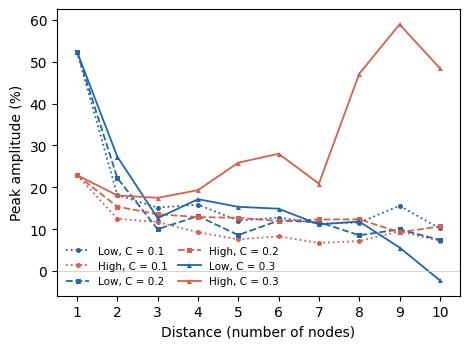

figure: figures_gamma\02\FIG_vFinal_A5_figure5_1graphe_pct.png


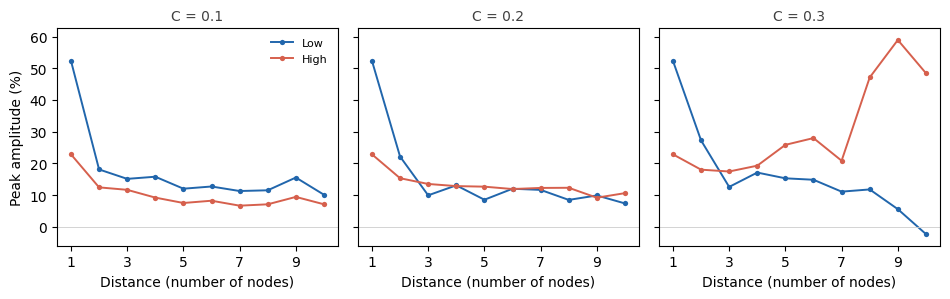

figure: figures_gamma\02\FIG_vFinal_A5_figure5_3graphes_pct.png


In [13]:
N_PRE_REL=N_PRE
def pic_causal_moyen_pct(nd, n_pre):
    m=np.asarray(nd["rs_m"], float)
    tt=(np.arange(len(m))-n_pre)*dt*1000
    pre=(tt>=-200)&(tt<-50)
    w=(tt>=0)&(tt<=150)
    b=float(m[pre].mean()) if np.any(pre) else float(nd["base_rs"])
    if not np.any(w):
        return float("nan")
    return float((m[w].max()-b)/max(abs(b), 1e-9)*100)

CACHE_REL=os.path.join(BASE, "propagation_relais_v6_cache.pkl")
PIC={}; BASES={}
if (not RECOMPUTE_FULL) and os.path.exists(CACHE_REL):
    with open(CACHE_REL, "rb") as f:
        saved=pickle.load(f)
    PIC=saved["PIC"]; BASES=saved["BASES"]
    print("cache relais v6")
else:
    n_use=N_STIM
    print("recalcul relais N=%d (cache v6)" % n_use, flush=True)
    for C in C_CHAIN_LIST:
        for lab in ("Low gamma", "High gamma"):
            print("  C=%.1f %s ..." % (C, lab), flush=True)
            nds=run_net_relais(STATES[lab]["Ele"], STATES[lab]["Eli"], C, n_use)
            PIC[(C, lab)]=np.array([pic_causal_moyen_pct(nd, N_PRE) for nd in nds])
            BASES[(C, lab)]=np.array([float(nd["base_rs"]) for nd in nds])
    with open(CACHE_REL, "wb") as f:
        pickle.dump({"PIC": PIC, "BASES": BASES}, f)

for C in C_CHAIN_LIST:
    for lab in ("Low gamma", "High gamma"):
        if (C, lab) in BASES:
            print("  baseline RS Hz  C=%.1f %s  %s" % (C, lab, np.array2string(BASES[(C, lab)], precision=2)))
if not PIC:
    print("aucune donnee relais pour tracer la figure")
else:
    x=np.arange(1,N_NODES_R+1)
    STYLE={0.1:":",0.2:"--",0.3:"-"}; MARK={0.1:"o",0.2:"s",0.3:"^"}
    COL={"Low gamma":C_LOW,"High gamma":C_HIGH}
    ymax=max(v.max() for v in PIC.values()); ymin=min(0.0,min(v.min() for v in PIC.values()))
    pad=0.06*(ymax-ymin); YL=(ymin-pad,ymax+pad)

    fig,ax=plt.subplots(figsize=(4.8,3.6))
    for C in C_CHAIN_LIST:
        for lab in ("Low gamma","High gamma"):
            if (C,lab) in PIC:
                ax.plot(x,PIC[(C,lab)],STYLE[C],color=COL[lab],marker=MARK[C],ms=3.6,lw=1.3,
                        mew=0.,label="%s, C = %g" % (lab.split()[0],C))
    ax.set_xlabel("Distance (number of nodes)")
    ax.set_ylabel("Peak amplitude (%)")
    ax.set_xticks(x); ax.set_xlim(0.5,N_NODES_R+0.5); ax.set_ylim(*YL)
    ax.axhline(0,color="0.8",lw=0.6); ax.grid(False)
    ax.legend(ncol=2,fontsize=7.5,frameon=False,handlelength=2.2,columnspacing=1.0)
    plt.tight_layout()
    fpath=os.path.join(FIGDIR,"FIG_vFinal_A5_figure5_1graphe_pct.png")
    plt.savefig(fpath,dpi=200,bbox_inches="tight"); plt.show(); print("figure: "+fpath)

    fig,axes=plt.subplots(1,3,figsize=(9.6,3.1),sharey=True)
    for j,C in enumerate(C_CHAIN_LIST):
        for lab in ("Low gamma","High gamma"):
            if (C,lab) in PIC:
                axes[j].plot(x,PIC[(C,lab)],"-",color=COL[lab],marker="o",ms=3.8,lw=1.4,
                             mew=0.,label=lab.split()[0])
        axes[j].set_title("C = %g" % C,fontsize=10,color="0.25")
        axes[j].set_xlabel("Distance (number of nodes)")
        axes[j].set_xticks(x[::2]); axes[j].set_xlim(0.5,N_NODES_R+0.5)
        axes[j].axhline(0,color="0.8",lw=0.6); axes[j].grid(False)
        if j==0:
            axes[j].set_ylabel("Peak amplitude (%)"); axes[j].set_ylim(*YL)
            axes[j].legend(fontsize=8,frameon=False)
    plt.tight_layout()
    fpath=os.path.join(FIGDIR,"FIG_vFinal_A5_figure5_3graphes_pct.png")
    plt.savefig(fpath,dpi=200,bbox_inches="tight"); plt.show(); print("figure: "+fpath)


---
## Same as 01 but with TVB

In [14]:
import sys, os, time, pickle, shutil
import numpy as np
RACINE = os.getcwd()
for _p in (RACINE, os.path.join(RACINE, "code"), os.path.join(RACINE, "tvb_model_reference", "simulation_file", "parameter")):
    if _p not in sys.path:
        sys.path.insert(0, _p)
import tvb.simulator.lab as lab_tvb
from tvb_model_reference.simulation_file.parameter.parameter_M_Berlin_ARTICLE import Parameter
import tvb_model_reference.src.nuu_tools_simulation_human2 as tools
import tvb_model_reference.src.Zerlaut_delay2 as Zerlaut_delay2

PARAM_MODULE = "parameter_M_Berlin_ARTICLE"
TAG_TVB = ""
DOSSIER_TVB = os.path.join("result", TAG_TVB + "tvb_article")
CACHE_TVB = os.path.join(BASE, "tvb_%sarticle_cache.pkl" % TAG_TVB)
ETATS_TVB = {"Low gamma": "Low", "High gamma": "High"}
for lab, e in ETATS_TVB.items():
    pm = Parameter(etat=e).parameter_model
    print("%-10s E_L_e = %s  E_L_i = %s  K_ext_e = %s  delay = %s  local_delay = %s"
          % (lab, pm["E_L_e"], pm["E_L_i"], pm["K_ext_e"], pm["delay"], pm["local_delay"]))
print("couplage :", Parameter().parameter_coupling)

C:\Users\fayre\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tvb\datatypes\surfaces.py:60: UserWarning: Geodesic distance module is unavailable; some functionality for surfaces will be unavailable.
  warnings.warn(msg)


Low gamma  E_L_e = -68.0  E_L_i = -58.0  K_ext_e = 400  delay = True  local_delay = 3.0
High gamma E_L_e = -58.0  E_L_i = -72.0  K_ext_e = 400  delay = True  local_delay = 3.0
couplage : {'type': 'Linear', 'parameter': {'a': 1.0, 'b': 0.0}}


In [15]:
N_CHAINE = 10
N = 10        
s_gauss = 1    
C_LIST = [0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0]

def matrice(geo, A):
    if geo in ("ff", "bidir"):
        W = np.zeros((N_CHAINE, N_CHAINE))
        L = np.abs(np.subtract.outer(np.arange(N_CHAINE), np.arange(N_CHAINE))).astype(float)
        for i in range(1, N_CHAINE):
            W[i, i-1] = A                    
            if geo == "bidir":
                W[i-1, i] = A                 
        return W, L
    if geo == "grille":                     
        Position = [[i, j] for i in range(N) for j in range(N)]
        L = np.array([[np.sqrt((a[0]-b[0])**2+(a[1]-b[1])**2) for b in Position] for a in Position])
        W = np.zeros((N**2, N**2))
        for i in range(N**2):
            for j in range(N**2):
                W[j, i] = A*np.exp(-0.5*(L[i, j]/s_gauss)**2)
        np.fill_diagonal(W, 0)
        return W, L
    return np.zeros((2, 2)), np.ones((2, 2))

CAS_TVB = [("bidir", 0), ("bidir", 5), ("ff", 5), ("ff", 0), ("grille", 45)]
NOMS = {"bidir": "bidirectionnel", "ff": "feedforward", "grille": "grille 2D"}

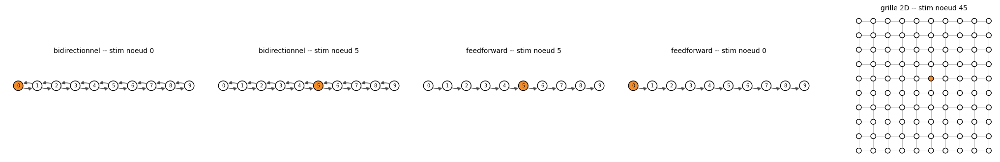

In [16]:
fig, axs = plt.subplots(1, len(CAS_TVB), figsize=(4.2*len(CAS_TVB), 3.4))
for ax, (geo, stim) in zip(axs, CAS_TVB):
    W, _ = matrice(geo, 1.0)
    n = len(W)
    xy = (np.array([[k % N, -(k // N)] for k in range(n)], float) if geo == "grille"
          else np.array([[k, 0] for k in range(n)], float))
    if geo == "grille":
        for i in range(n):
            for j in range(i+1, n):
                if np.hypot(*(xy[i]-xy[j])) == 1:
                    ax.plot(*zip(xy[i], xy[j]), color="0.75", lw=0.8, zorder=0)
    else:
        for i in range(n):
            for j in range(n):
                if W[i, j] > 0:
                    ax.annotate("", xy=xy[i], xytext=xy[j],
                                arrowprops=dict(arrowstyle="-|>", color="0.3", shrinkA=8, shrinkB=8,
                                                mutation_scale=10, connectionstyle="arc3,rad=0.3"))
    col = ["#F28E2B" if k == stim else "white" for k in range(n)]
    ax.scatter(xy[:, 0], xy[:, 1], s=200 if n <= 10 else 55, c=col, edgecolors="k", zorder=3)
    if n <= 10:
        for k in range(n):
            ax.text(xy[k, 0], xy[k, 1], str(k), ha="center", va="center", fontsize=7, zorder=4)
        ax.set_xlim(-0.7, n-0.3); ax.set_ylim(-1.5, 1.5)
    ax.set_title("%s -- stim noeud %d" % (NOMS[geo], stim), fontsize=10)
    ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIGDIR, "TVB_%sschema_reseaux.png" % TAG_TVB), dpi=150, bbox_inches="tight")
plt.show()

In [17]:
def sta_pic(E, tt, temps_ms, per):
    npre, npost = int(round(200/per)), int(round(600/per))
    idx = np.searchsorted(tt, temps_ms)
    wins = np.array([E[i-npre:i+npost] for i in idx if i-npre >= 0 and i+npost <= len(E)])
    m = wins.mean(0); t = np.arange(-npre, npost)*per
    pre = (t >= -200) & (t < -50); w = (t >= 0) & (t <= 150)
    b = m[pre].mean(0)
    return dict(pic=(m[w].max(0)-b)/np.maximum(np.abs(b), 1e-9)*100, base=b, m=m, t=t, n=len(wins))

def simule_tvb(geo, stim, A, lab, n_stim, racine, duree_s=None):
    import sys, os, shutil, importlib
    import numpy as np
    os.chdir(racine)
    for _p in (racine, os.path.join(racine, "code"), os.path.join(racine, "tvb_model_reference", "simulation_file", "parameter")):
        if _p not in sys.path:
            sys.path.insert(0, _p)
    import tvb.simulator.lab as lab_tvb
    import tvb_model_reference.src.nuu_tools_simulation_human2 as tools
    import tvb_model_reference.src.Zerlaut_delay2 as Zerlaut_delay2
    Par = importlib.import_module("tvb_model_reference.simulation_file.parameter." + PARAM_MODULE).Parameter
    rep = os.path.join(racine, DOSSIER_TVB, "%s_stim%d_C%g_%s" % (geo, stim, A, lab.split()[0]))
    W, L = matrice(geo, A)
    per = 1.0 if len(W) > 10 else 0.1                        

    def une_simulation(stim_kHz, T_TOT):
        shutil.rmtree(rep, ignore_errors=True); os.makedirs(os.path.join(rep, "conn"))
        np.savetxt(os.path.join(rep, "conn", "weights.txt"), W)
        np.savetxt(os.path.join(rep, "conn", "tract_lengths.txt"), L)
        Zerlaut_delay2.Zerlaut_adaptation_first_order.stim_kHz = stim_kHz
        Zerlaut_delay2.Zerlaut_adaptation_first_order.stim_noeud = stim
        p = Par(etat=ETATS_TVB[lab])
        p.parameter_connection_between_region['path'] = os.path.join(rep, "conn")
        p.parameter_simulation['path_result'] = rep + "/"
        sim = tools.init(p.parameter_simulation, p.parameter_model, p.parameter_connection_between_region,
                         p.parameter_coupling, p.parameter_integrator, p.parameter_monitor)
        # on n'enregistre que le taux RS (sinon ~1 Go par simulation)
        sim.monitors = (lab_tvb.monitors.TemporalAverage(variables_of_interest=np.array([0]), period=per),)
        for _m in sim.monitors:
            _m.config_for_sim(sim)
        tools.run_simulation(sim, T_TOT*1e3, p.parameter_simulation, p.parameter_monitor)
        r = tools.get_result(rep, 0, T_TOT*1e3 - 1)
        shutil.rmtree(rep, ignore_errors=True)                   
        return r[0][0], r[0][1][:, 0, :]*1e3                    

    if geo == "isole":
        tt, E = une_simulation(None, duree_s)
        return dict(t=tt, E=E[:, 0])
    T_ST = make_stim_rand(n_stim); T_TOT = float(T_ST[-1] + 1.5)        
    t = np.arange(int(round(T_TOT*1e4)))*0.1
    imp = np.zeros_like(t)
    for ts in T_ST:
        imp += AMP*np.exp(-0.5*((t - ts*1e3)/10.)**2)           
    tt, Es = une_simulation(imp*1e-3, T_TOT)                  
    tt_c, Ec = une_simulation(None, T_TOT)                     
    n = min(len(Es), len(Ec)); Es, Ec, tt = Es[:n], Ec[:n], tt[:n]

    npre, npost = int(round(200/per)), int(round(600/per))
    idx = [i for i in np.searchsorted(tt, T_ST*1e3) if i-npre >= 0 and i+npost <= n]
    ws = np.array([Es[i-npre:i+npost] for i in idx]); wc = np.array([Ec[i-npre:i+npost] for i in idx])
    tw = np.arange(-npre, npost)*per
    pre = (tw >= -200) & (tw < -50); fen = (tw >= 0) & (tw <= 150)
    ms, mc = ws.mean(0), wc.mean(0)
    b = ms[pre].mean(0); bc = mc[pre].mean(0)
    d = ws - wc; dm = d.mean(0); dsem = d.std(0, ddof=1)/np.sqrt(len(d))
    k = np.argmax(dm[fen], axis=0)
    return dict(pic=(ms[fen].max(0)-b)/np.maximum(np.abs(b), 1e-9)*100,          
                plancher=(mc[fen].max(0)-bc)/np.maximum(np.abs(bc), 1e-9)*100,   
                base=b, dpic_hz=dm[fen].max(0), dpic_sem=dsem[fen][k, np.arange(dm.shape[1])],
                t_ms=tw.astype(np.float32), d_m=dm.astype(np.float32),
                rs_m=ms.astype(np.float32), ctl_m=mc.astype(np.float32), n_essais=len(d))

In [18]:
def lire_E(rep):
    fic = sorted([f for f in os.listdir(rep) if f.startswith("step_") and f[5:-4].isdigit()], key=lambda f: int(f[5:-4]))
    ts, es = [], []
    for f in fic:
        a = np.load(os.path.join(rep, f), allow_pickle=True)
        if a.size == 0 or len(a[0]) == 0:
            continue
        ts.append(np.array([x[0] for x in a[0]], float))
        es.append(np.array([np.asarray(x[1])[0, :, 0] for x in a[0]], np.float32))
    return np.concatenate(ts), np.concatenate(es)*1e3          # ms, Hz

def simule_groupe(conds, n_stim, racine):
    import sys, os, shutil, importlib
    import numpy as np
    os.chdir(racine)
    for _p in (racine, os.path.join(racine, "code"), os.path.join(racine, "tvb_model_reference", "simulation_file", "parameter")):
        if _p not in sys.path:
            sys.path.insert(0, _p)
    import tvb.simulator.lab as lab_tvb
    import tvb_model_reference.src.nuu_tools_simulation_human2 as tools
    import tvb_model_reference.src.Zerlaut_delay2 as Zerlaut_delay2
    Par = importlib.import_module("tvb_model_reference.simulation_file.parameter." + PARAM_MODULE).Parameter
    geo = conds[0][0]
    mats = [matrice(g, A) for (g, s, A, lab) in conds]
    nb = len(mats[0][0]); NT = nb*len(conds)
    W = np.zeros((NT, NT)); L = np.ones((NT, NT))           
    E_Le = np.zeros(NT); E_Li = np.zeros(NT); stims = []
    for b, ((g, s, A, lab), (Wb, Lb)) in enumerate(zip(conds, mats)):
        sl = slice(b*nb, (b+1)*nb)
        W[sl, sl] = Wb; L[sl, sl] = Lb
        pm = Par(etat=ETATS_TVB[lab]).parameter_model
        E_Le[sl] = pm["E_L_e"]; E_Li[sl] = pm["E_L_i"]
        stims.append(b*nb + s)
    per = 1.0 if nb > 10 else 0.5                             
    rep = os.path.join(racine, DOSSIER_TVB, "groupe_%s_%d_%s_%s" % (geo, conds[0][1], conds[0][3].split()[0], "_".join("%g" % c[2] for c in conds)[:60]))
    T_ST = make_stim_rand(n_stim); T_TOT = float(T_ST[-1] + 1.5)        
    t = np.arange(int(round(T_TOT*1e4)))*0.1
    imp = np.zeros_like(t)
    for ts in T_ST:
        imp += AMP*np.exp(-0.5*((t - ts*1e3)/10.)**2)            

    def une_simulation(stim_kHz):
        shutil.rmtree(rep, ignore_errors=True); os.makedirs(os.path.join(rep, "conn"))
        np.savetxt(os.path.join(rep, "conn", "weights.txt"), W)
        np.savetxt(os.path.join(rep, "conn", "tract_lengths.txt"), L)
        Zerlaut_delay2.Zerlaut_adaptation_first_order.stim_kHz = stim_kHz
        Zerlaut_delay2.Zerlaut_adaptation_first_order.stim_noeud = stims
        p = Par(etat="Low")
        p.parameter_model["E_L_e"] = E_Le.reshape(-1, 1).tolist(); p.parameter_model["E_L_i"] = E_Li.reshape(-1, 1).tolist()   
        p.parameter_connection_between_region['path'] = os.path.join(rep, "conn")
        p.parameter_simulation['path_result'] = rep + "/"
        sim = tools.init(p.parameter_simulation, p.parameter_model, p.parameter_connection_between_region,
                         p.parameter_coupling, p.parameter_integrator, p.parameter_monitor)
        sim.monitors = (lab_tvb.monitors.TemporalAverage(variables_of_interest=np.array([0]), period=per),)
        for _m in sim.monitors:
            _m.config_for_sim(sim)
        tools.run_simulation(sim, T_TOT*1e3, p.parameter_simulation, p.parameter_monitor)
        tt, E = lire_E(rep)
        shutil.rmtree(rep, ignore_errors=True)
        return tt, E

    tt, Es = une_simulation(imp*1e-3)
    tt_c, Ec = une_simulation(None)                      
    n = min(len(Es), len(Ec)); tt, Es, Ec = tt[:n], Es[:n], Ec[:n]
    npre, npost = int(round(200/per)), int(round(600/per))
    idx = [i for i in np.searchsorted(tt, T_ST*1e3) if i-npre >= 0 and i+npost <= n]
    tw = np.arange(-npre, npost)*per
    pre = (tw >= -200) & (tw < -50); fen = (tw >= 0) & (tw <= 150)
    out = {}
    for b, cle in enumerate(conds):
        sl = slice(b*nb, (b+1)*nb)
        ws = np.array([Es[i-npre:i+npost, sl] for i in idx]); wc = np.array([Ec[i-npre:i+npost, sl] for i in idx])
        ms, mc = ws.mean(0), wc.mean(0)
        bs, bc = ms[pre].mean(0), mc[pre].mean(0)
        d = ws - wc; dm = d.mean(0); dsem = d.std(0, ddof=1)/np.sqrt(len(d))
        k = np.argmax(dm[fen], axis=0)
        out[cle] = dict(pic=(ms[fen].max(0)-bs)/np.maximum(np.abs(bs), 1e-9)*100,
                        plancher=(mc[fen].max(0)-bc)/np.maximum(np.abs(bc), 1e-9)*100,
                        base=bs, dpic_hz=dm[fen].max(0), dpic_sem=dsem[fen][k, np.arange(nb)],
                        t_ms=tw.astype(np.float32), d_m=dm.astype(np.float32),
                        rs_m=ms.astype(np.float32), ctl_m=mc.astype(np.float32), n_essais=len(d))
        del ws, wc, d
    return out

In [19]:
## Test
from scipy.signal import welch
CIBLE = {"Low gamma": (1.41, 85.4), "High gamma": (5.16, 61.0)}   
for lab in ETATS_TVB:
    r = simule_tvb("isole", 0, 0.0, lab, 0, RACINE, duree_s=10.0)
    x = r["E"][r["t"] > 2000]
    f, P_ = welch(x - x.mean(), fs=1e4, nperseg=8192); mk = (f > 20) & (f < 150)
    print("%-10s base %5.2f Hz (champ moyen %.2f)   pic gamma %5.1f Hz (champ moyen %.1f)   ecart-type %.2f Hz"
          % (lab, x.mean(), CIBLE[lab][0], f[mk][P_[mk].argmax()], CIBLE[lab][1], x.std()))

BUFFERRR: and (101, 2, 2, 1)


simulation time :1000.0500000000001


simulation time :2000.0500000000002


simulation time :3000.05


simulation time :4000.05


simulation time :5000.05


... (11 outputs left out)

simulation time :7000.05


simulation time :8000.05


simulation time :9000.050000000001


High gamma base  5.21 Hz (champ moyen 5.16)   pic gamma  61.0 Hz (champ moyen 61.0)   ecart-type 2.55 Hz


In [20]:
import ctypes
from joblib import Parallel, delayed

def _go_libres():
    try:
        class M(ctypes.Structure):
            _fields_ = [("l", ctypes.c_ulong), ("p", ctypes.c_ulong), ("t", ctypes.c_ulonglong),
                        ("a", ctypes.c_ulonglong), ("tp", ctypes.c_ulonglong), ("ap", ctypes.c_ulonglong),
                        ("tv", ctypes.c_ulonglong), ("av", ctypes.c_ulonglong), ("e", ctypes.c_ulonglong)]
        m = M(); m.l = ctypes.sizeof(M)
        ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(m))
        return m.a/1e9
    except Exception:
        try:
            for l in open("/proc/meminfo"):
                if l.startswith("MemAvailable"):
                    return int(l.split()[1])/1e6
        except Exception:
            pass
    return 6.0

N_PROC_TVB = max(1, min(8, (os.cpu_count() or 2) - 1, int((_go_libres() - 2)/1.5)))   
RES_TVB = pickle.load(open(CACHE_TVB, "rb")) if os.path.exists(CACHE_TVB) else {}
GRILLE_C = [A for A in C_LIST if A <= 0.1]
GROUPES = []
for (g, s) in CAS_TVB:
    if g == "grille":
        for lab in ETATS_TVB:                                    
            GROUPES.append([(g, s, A, lab) for A in GRILLE_C])
    else:                                                        
        GROUPES.append([(g, s, A, lab) for A in C_LIST for lab in ETATS_TVB])
GROUPES = [gr for gr in GROUPES if any(c not in RES_TVB for c in gr)]
print("deja en cache : %d conditions ; groupes a simuler : %d (x2 : stim + controle) ; en parallele : %d"
      % (len(RES_TVB), len(GROUPES), N_PROC_TVB), flush=True)
t0 = time.time()
for i in range(0, len(GROUPES), N_PROC_TVB):
    lot = GROUPES[i:i+N_PROC_TVB]
    for out in Parallel(n_jobs=N_PROC_TVB)(delayed(simule_groupe)(gr, N_STIM, RACINE) for gr in lot):
        RES_TVB.update(out)
        for cle, r in out.items():
            print("  %-6s stim %2d  C=%-4g %-10s pic %.1f %%  plancher (controle) %.1f %%"
                  % (cle[0], cle[1], cle[2], cle[3], r["pic"][cle[1]], r["plancher"][cle[1]]), flush=True)
    pickle.dump(RES_TVB, open(CACHE_TVB, "wb"))
    print("  -> groupes %d / %d, %.0f min" % (min(i+N_PROC_TVB, len(GROUPES)), len(GROUPES), (time.time()-t0)/60), flush=True)

deja en cache : 70 conditions ; groupes a simuler : 0 (x2 : stim + controle) ; en parallele : 1


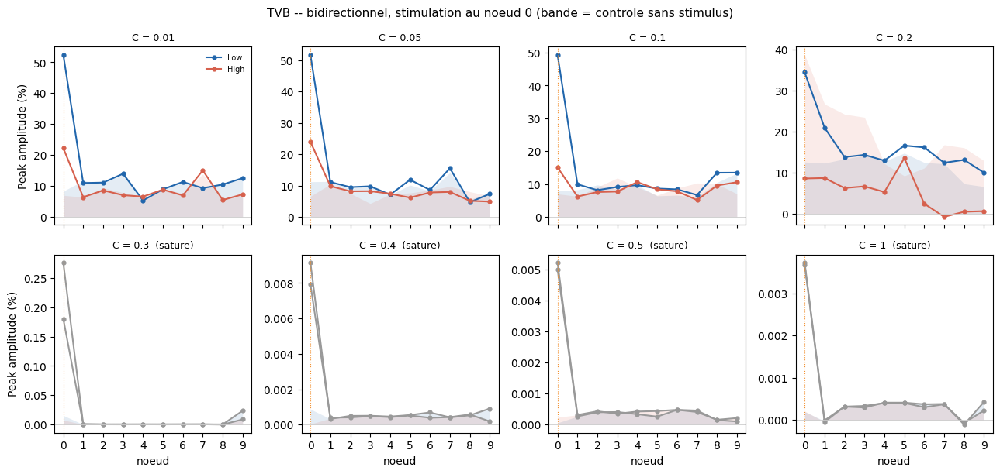

figure: figures_gamma\02\TVB_propagation_bidir_stim0.png


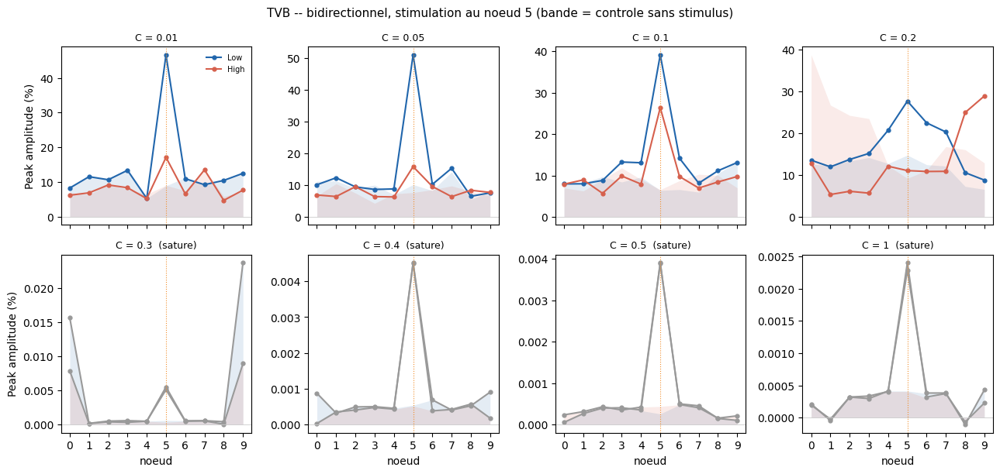

figure: figures_gamma\02\TVB_propagation_bidir_stim5.png


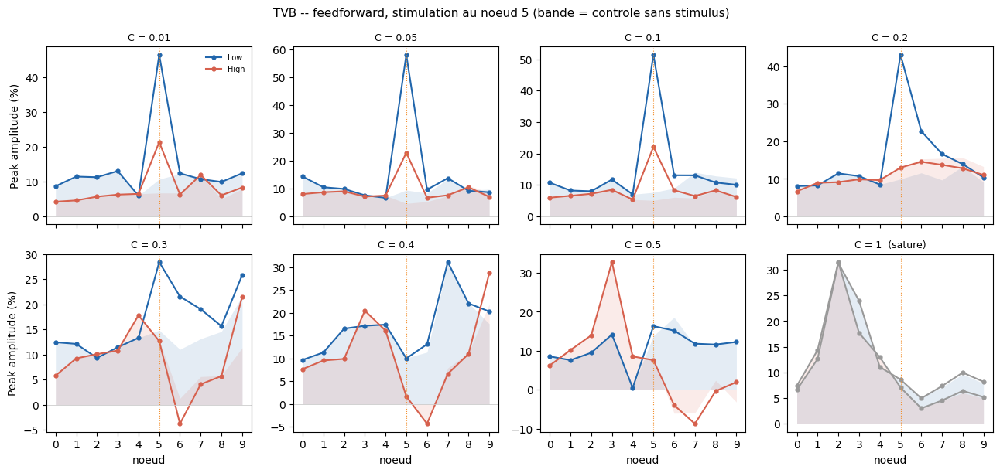

figure: figures_gamma\02\TVB_propagation_ff_stim5.png


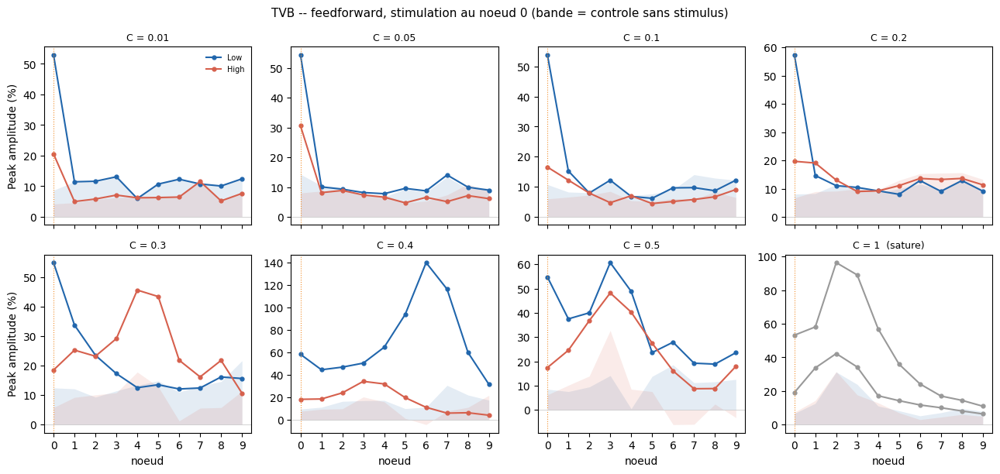

figure: figures_gamma\02\TVB_propagation_ff_stim0.png


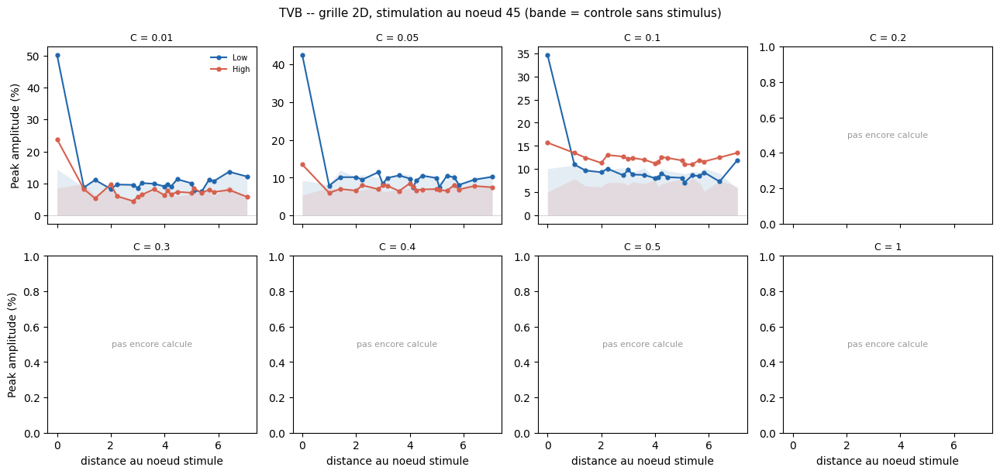

figure: figures_gamma\02\TVB_propagation_grille_stim45.png
C=0.1  Low gamma  ff    stim 0 : pic [53.8 15.2  7.9 12.2  6.8]   plancher [10.7  8.2  8.  11.7  7. ]
C=0.1  Low gamma  bidir stim 0 : pic [49.4  9.9  8.1  9.1  9.7]   plancher [8.  8.2 9.7 8.4 9.6]
C=0.1  High gamma ff    stim 0 : pic [16.5 12.2  7.9  4.7  7. ]   plancher [6.  6.6 7.2 8.5 5.4]
C=0.1  High gamma bidir stim 0 : pic [15.   6.2  7.6  7.7 10.6]   plancher [ 7.   6.3  9.1 11.8  9. ]
C=0.2  Low gamma  ff    stim 0 : pic [57.4 14.6 11.  10.4  9.2]   plancher [ 8.1  8.3 11.5 10.7  8.5]
C=0.2  Low gamma  bidir stim 0 : pic [34.4 20.9 13.8 14.3 12.9]   plancher [12.6 12.3 13.3 14.2 12.7]
C=0.2  High gamma ff    stim 0 : pic [19.7 19.1 13.   9.   9.2]   plancher [6.7 8.9 9.1 9.9 9.7]
C=0.2  High gamma bidir stim 0 : pic [8.6 8.7 6.2 6.6 5.3]   plancher [38.7 26.7 24.2 23.5 12.2]


In [21]:
COL_TVB = {"Low gamma": C_LOW, "High gamma": C_HIGH}
SATURE = 150.
def par_distance(v, stim):
    dist = np.array([np.hypot(k//N - stim//N, k % N - stim % N) for k in range(N*N)])
    ud = np.unique(dist)
    return ud, np.array([v[dist == u].mean() for u in ud])

for (geo, stim) in CAS_TVB:
    if not any((geo, stim, A, l) in RES_TVB for A in C_LIST for l in ETATS_TVB):
        print("%s stim %d : rien a tracer pour l'instant" % (NOMS[geo], stim)); continue
    fig, axs = plt.subplots(2, 4, figsize=(13, 6.2), sharex=True)
    for j, A in enumerate(C_LIST):
        ax = axs[j//4, j % 4]
        dispo = [l for l in ETATS_TVB if (geo, stim, A, l) in RES_TVB]
        if not dispo:
            ax.text(0.5, 0.5, "pas encore calcule", transform=ax.transAxes, ha="center", va="center", fontsize=8, color="0.6")
        sat = any(RES_TVB[(geo, stim, A, l)]["base"].max() > SATURE for l in dispo)
        for lab in dispo:
            r = RES_TVB[(geo, stim, A, lab)]
            if geo == "grille":
                x, y = par_distance(r["pic"], stim); _, fl = par_distance(r["plancher"], stim)
            else:
                x, y, fl = np.arange(N_CHAINE), r["pic"], r["plancher"]
            ax.fill_between(x, 0, fl, color=COL_TVB[lab], alpha=0.12, lw=0)
            ax.plot(x, y, "-o", ms=3.5, color=(COL_TVB[lab] if not sat else "0.6"), label=lab.split()[0])
        if geo != "grille":
            ax.axvline(stim, color="#F28E2B", ls=":", lw=0.8); ax.set_xticks(range(N_CHAINE))
        ax.axhline(0, color="0.8", lw=0.6)
        ax.set_title("C = %g%s" % (A, "  (sature)" if sat else ""), fontsize=9)
        if j % 4 == 0: ax.set_ylabel("Peak amplitude (%)")
        if j >= 4: ax.set_xlabel("distance au noeud stimule" if geo == "grille" else "noeud")
        if j == 0: ax.legend(fontsize=7, frameon=False)
    fig.suptitle("TVB %s-- %s, stimulation au noeud %d (bande = controle sans stimulus)" % (TAG_TVB.replace("_", " "), NOMS[geo], stim), fontsize=11)
    plt.tight_layout()
    fp = os.path.join(FIGDIR, "TVB_%spropagation_%s_stim%d.png" % (TAG_TVB, geo, stim))
    plt.savefig(fp, dpi=150, bbox_inches="tight"); plt.show(); print("figure: " + fp)

for A in (0.1, 0.2):
    for lab in ETATS_TVB:
        for geo in ("ff", "bidir"):
            if (geo, 0, A, lab) in RES_TVB:
                r = RES_TVB[(geo, 0, A, lab)]
                print("C=%-4g %-10s %-5s stim 0 : pic %s   plancher %s" % (A, lab, geo,
                      np.array2string(r["pic"][:5], precision=1), np.array2string(r["plancher"][:5], precision=1)))

In [22]:
PRE_MS, FEN_MS = (-200, -50), (0, 150)        
C_TRACE = 0.1                                

def profil(v, geo, stim):
    if geo == "grille":
        dist = np.array([np.hypot(k//N - stim//N, k % N - stim % N) for k in range(N*N)])
    elif geo == "ff":
        dist = (np.arange(N_CHAINE) - stim).astype(float)        # feedforward 
        dist[dist < 0] = np.nan
    else:
        dist = np.abs(np.arange(N_CHAINE) - stim).astype(float)  # bidirectionnel 
    ud = np.unique(dist[~np.isnan(dist)])
    v = np.asarray(v)
    return ud, np.array([v[..., dist == u].mean(-1) for u in ud]).T if v.ndim > 1 else np.array([v[dist == u].mean() for u in ud])

def masques(t):
    return (t >= PRE_MS[0]) & (t < PRE_MS[1]), (t >= FEN_MS[0]) & (t <= FEN_MS[1])

def en_pct(y, t):
    pre, _ = masques(t)
    b = y[pre].mean(0)
    return (y - b)/np.maximum(np.abs(b), 1e-9)*100

def stim_moins_ctl_pct(r):
    t = r["t_ms"]; pre, fen = masques(t)
    bc = np.maximum(np.abs(r["ctl_m"][pre].mean(0)), 1e-9)
    return r["d_m"]/bc*100, r["d_m"][fen].max(0)/bc*100, r["dpic_sem"]/bc*100

def sature(r):
    return r["base"].max() > SATURE

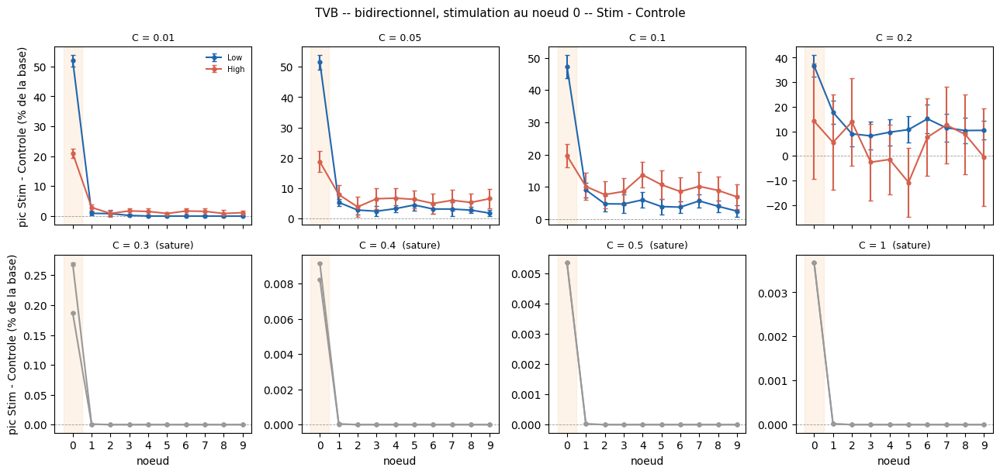

figure: figures_gamma\02\TVB_PCT_STIM_MOINS_CONTROLE_bidir_stim0.png


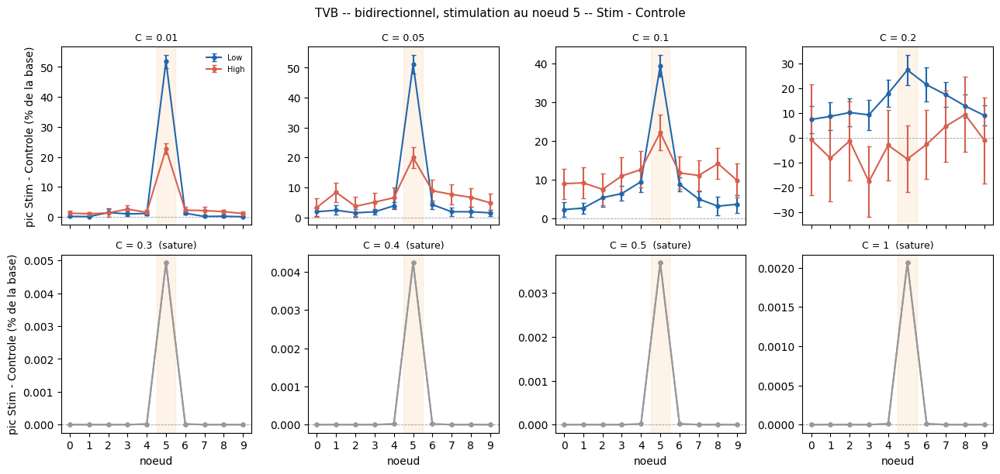

figure: figures_gamma\02\TVB_PCT_STIM_MOINS_CONTROLE_bidir_stim5.png


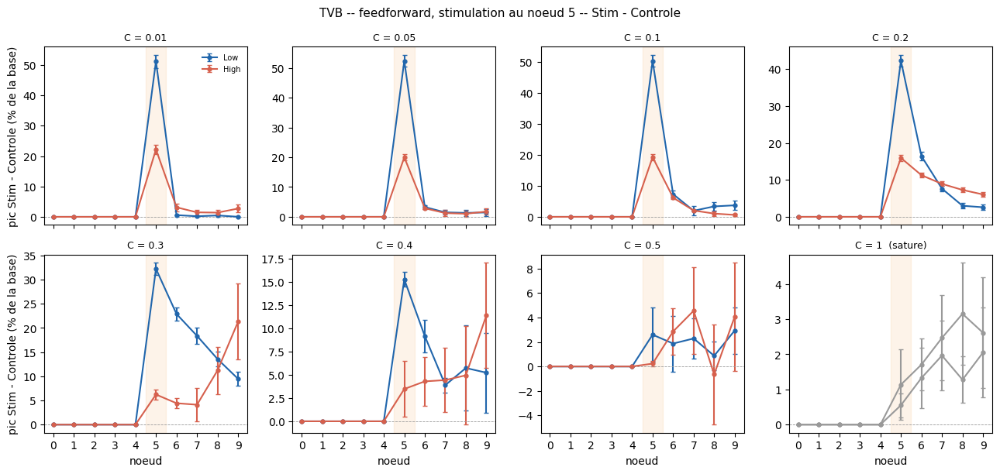

figure: figures_gamma\02\TVB_PCT_STIM_MOINS_CONTROLE_ff_stim5.png


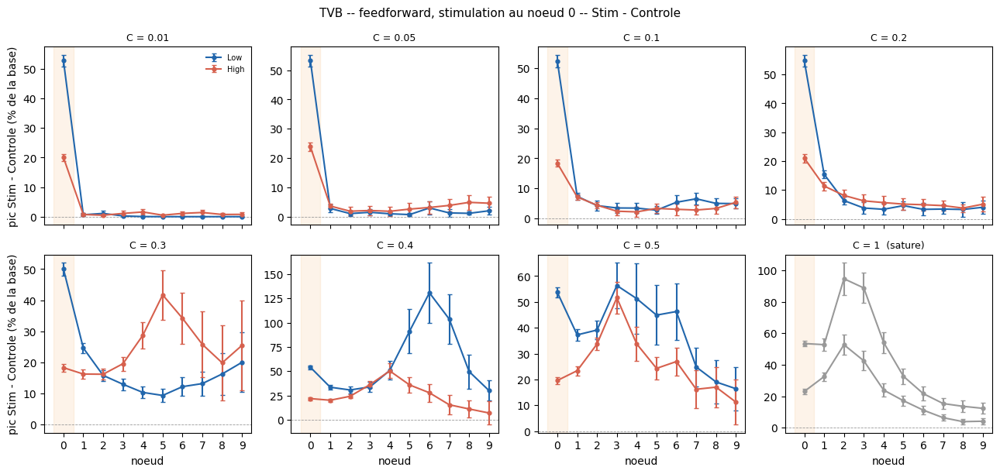

figure: figures_gamma\02\TVB_PCT_STIM_MOINS_CONTROLE_ff_stim0.png


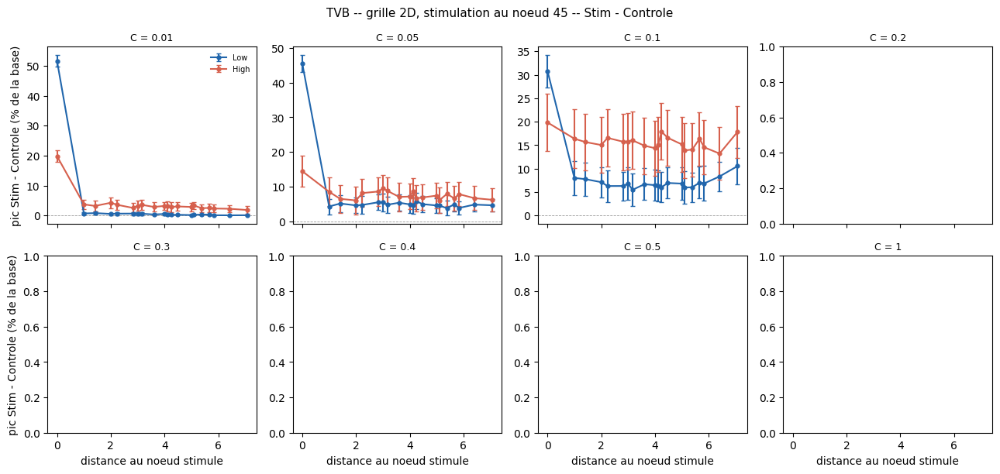

figure: figures_gamma\02\TVB_PCT_STIM_MOINS_CONTROLE_grille_stim45.png


In [23]:
for (geo, stim) in CAS_TVB:
    if not any((geo, stim, A, l) in RES_TVB for A in C_LIST for l in ETATS_TVB):
        continue
    fig, axs = plt.subplots(2, 4, figsize=(13, 6.2), sharex=True)
    for j, A in enumerate(C_LIST):
        ax = axs[j//4, j % 4]
        dispo = [l for l in ETATS_TVB if (geo, stim, A, l) in RES_TVB]
        sat = any(sature(RES_TVB[(geo, stim, A, l)]) for l in dispo)
        for lab in dispo:
            _, y, e = stim_moins_ctl_pct(RES_TVB[(geo, stim, A, lab)])
            if geo == "grille":
                x, y = profil(y, geo, stim); _, e = profil(e, geo, stim)
            else:
                x = np.arange(N_CHAINE)
            ax.errorbar(x, y, yerr=e, fmt="-o", ms=3.5, capsize=2, color=(COL_TVB[lab] if not sat else "0.6"), label=lab.split()[0])
        if geo != "grille":
            ax.axvspan(stim-0.5, stim+0.5, color="#F28E2B", alpha=0.10); ax.set_xticks(range(N_CHAINE))
        ax.axhline(0, color="0.6", lw=0.6, ls="--")
        ax.set_title("C = %g%s" % (A, "  (sature)" if sat else ""), fontsize=9)
        if j % 4 == 0: ax.set_ylabel("pic Stim - Controle (% de la base)")
        if j >= 4: ax.set_xlabel("distance au noeud stimule" if geo == "grille" else "noeud")
        if j == 0: ax.legend(fontsize=7, frameon=False)
    fig.suptitle("TVB %s-- %s, stimulation au noeud %d -- Stim - Controle" % (TAG_TVB.replace("_", " "), NOMS[geo], stim), fontsize=11)
    plt.tight_layout()
    fp = os.path.join(FIGDIR, "TVB_%sPCT_STIM_MOINS_CONTROLE_%s_stim%d.png" % (TAG_TVB, geo, stim))
    plt.savefig(fp, dpi=150, bbox_inches="tight"); plt.show(); print("figure: " + fp)

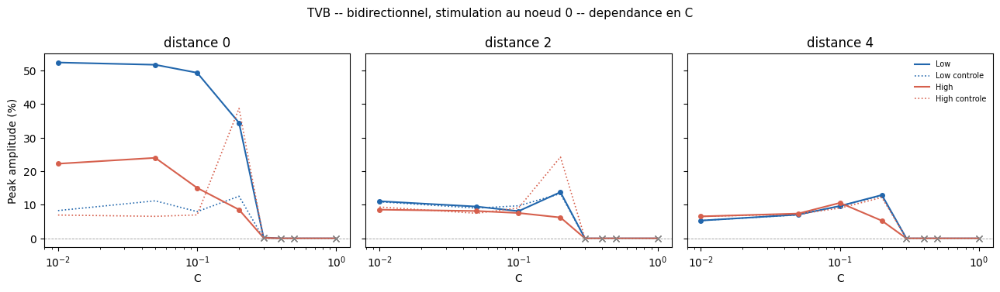

figure: figures_gamma\02\TVB_PCT_DEPENDANCE_C_bidir_stim0.png


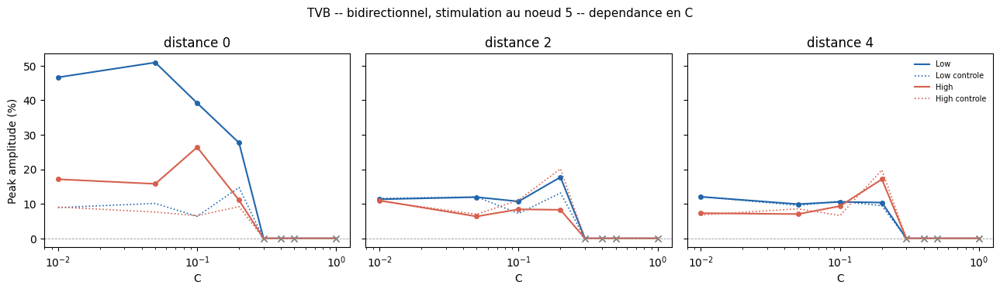

figure: figures_gamma\02\TVB_PCT_DEPENDANCE_C_bidir_stim5.png


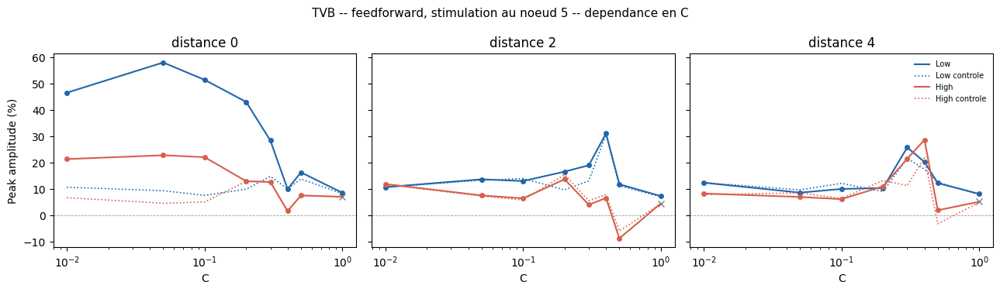

figure: figures_gamma\02\TVB_PCT_DEPENDANCE_C_ff_stim5.png


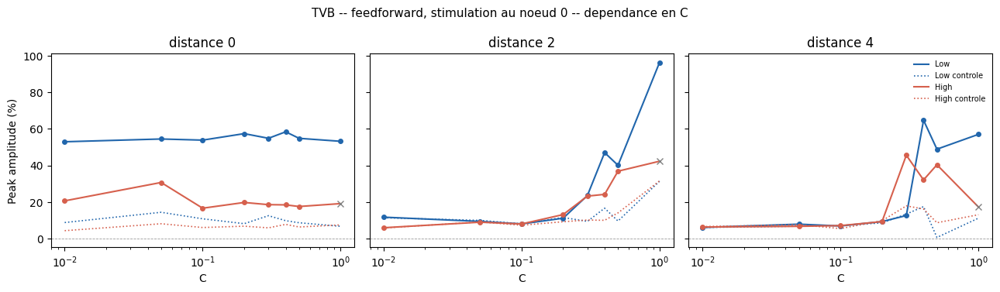

figure: figures_gamma\02\TVB_PCT_DEPENDANCE_C_ff_stim0.png


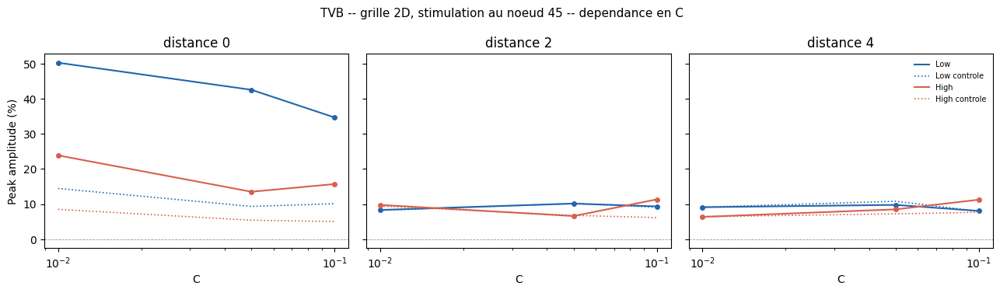

figure: figures_gamma\02\TVB_PCT_DEPENDANCE_C_grille_stim45.png


In [24]:
for (geo, stim) in CAS_TVB:
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
    vide = True
    for ax, dd in zip(axs, (0, 2, 4)):
        for lab in ETATS_TVB:
            xs, ys, fs, ss = [], [], [], []
            for A in C_LIST:
                if (geo, stim, A, lab) in RES_TVB:
                    r = RES_TVB[(geo, stim, A, lab)]
                    ud, y = profil(r["pic"], geo, stim); _, f = profil(r["plancher"], geo, stim)
                    if dd in ud:
                        k = list(ud).index(dd)
                        xs.append(A); ys.append(y[k]); fs.append(f[k]); ss.append(sature(r))
            if xs:
                vide = False
                xs, ys, fs, ss = map(np.array, (xs, ys, fs, ss))
                ax.plot(xs, ys, "-", color=COL_TVB[lab], label=lab.split()[0])
                ax.plot(xs[~ss], ys[~ss], "o", ms=4, color=COL_TVB[lab])
                ax.plot(xs[ss], ys[ss], "x", ms=6, color="0.5")
                ax.plot(xs, fs, ":", lw=1.2, color=COL_TVB[lab], label=lab.split()[0] + " controle")
        ax.set_xscale("log"); ax.axhline(0, color="0.6", lw=0.6, ls="--")
        ax.set_title("distance %d" % dd); ax.set_xlabel("C")
    if vide:
        plt.close(fig); continue
    axs[0].set_ylabel("Peak amplitude (%)"); axs[-1].legend(fontsize=7, frameon=False)
    fig.suptitle("TVB %s-- %s, stimulation au noeud %d -- dependance en C" % (TAG_TVB.replace("_", " "), NOMS[geo], stim), fontsize=11)
    plt.tight_layout()
    fp = os.path.join(FIGDIR, "TVB_%sPCT_DEPENDANCE_C_%s_stim%d.png" % (TAG_TVB, geo, stim))
    plt.savefig(fp, dpi=150, bbox_inches="tight"); plt.show(); print("figure: " + fp)

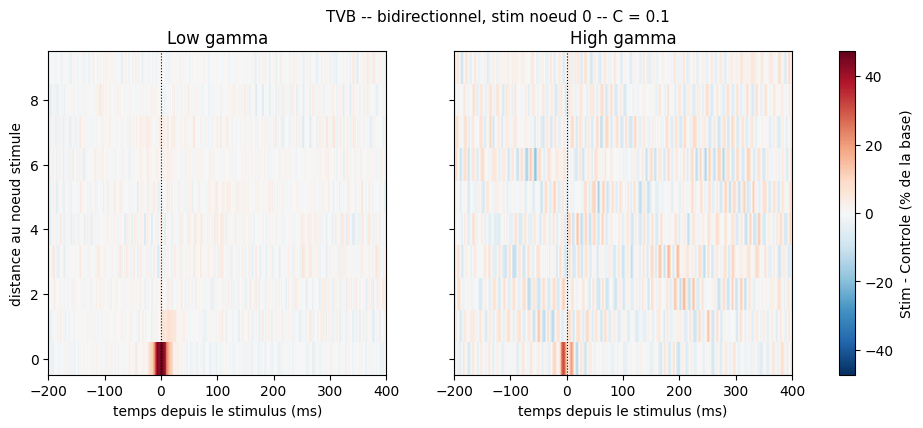

figure: figures_gamma\02\TVB_PCT_TEMPS_DISTANCE_bidir_stim0_C0.1.png


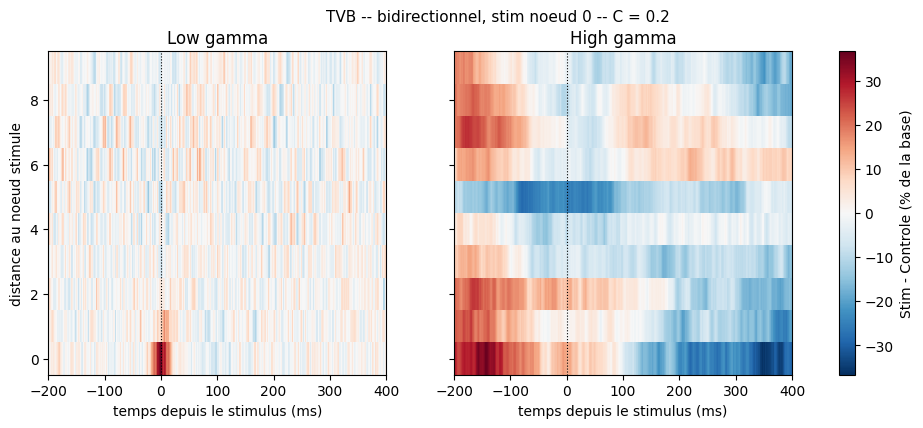

figure: figures_gamma\02\TVB_PCT_TEMPS_DISTANCE_bidir_stim0_C0.2.png


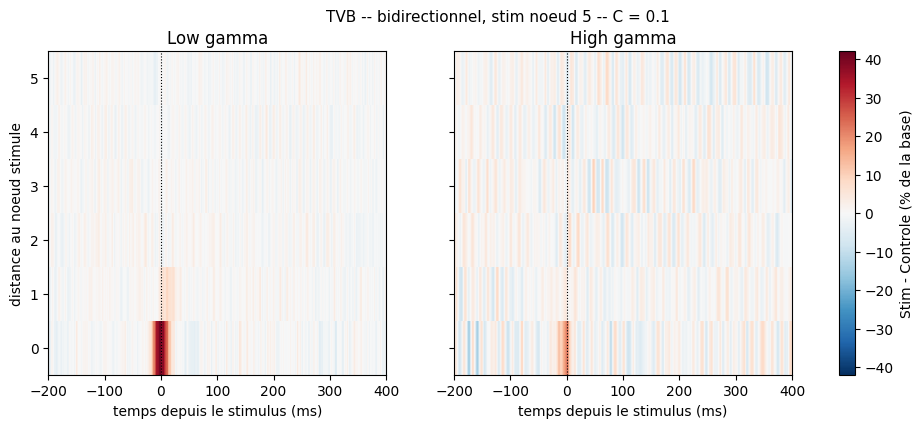

figure: figures_gamma\02\TVB_PCT_TEMPS_DISTANCE_bidir_stim5_C0.1.png


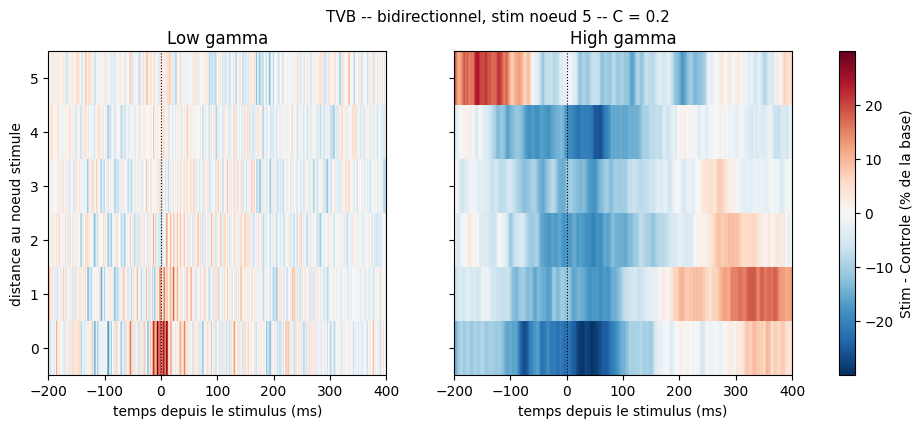

figure: figures_gamma\02\TVB_PCT_TEMPS_DISTANCE_bidir_stim5_C0.2.png


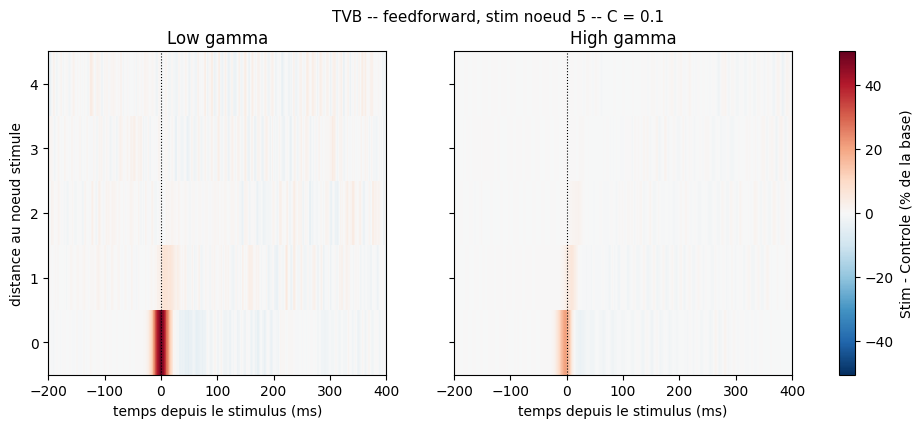

figure: figures_gamma\02\TVB_PCT_TEMPS_DISTANCE_ff_stim5_C0.1.png


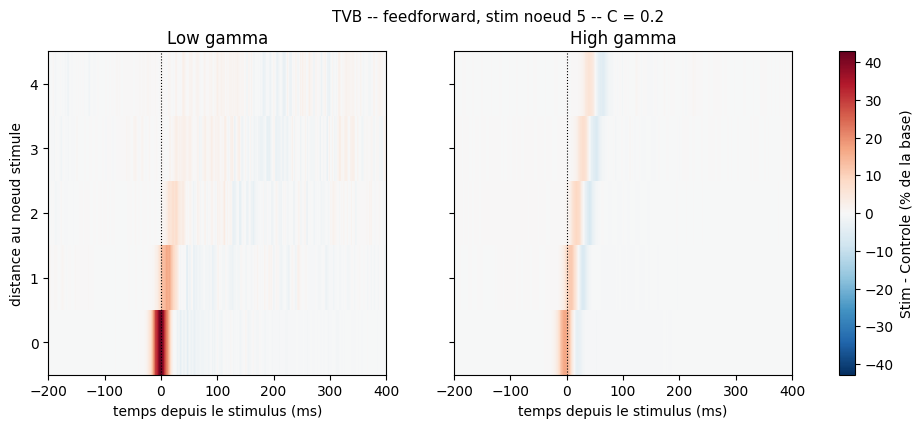

figure: figures_gamma\02\TVB_PCT_TEMPS_DISTANCE_ff_stim5_C0.2.png


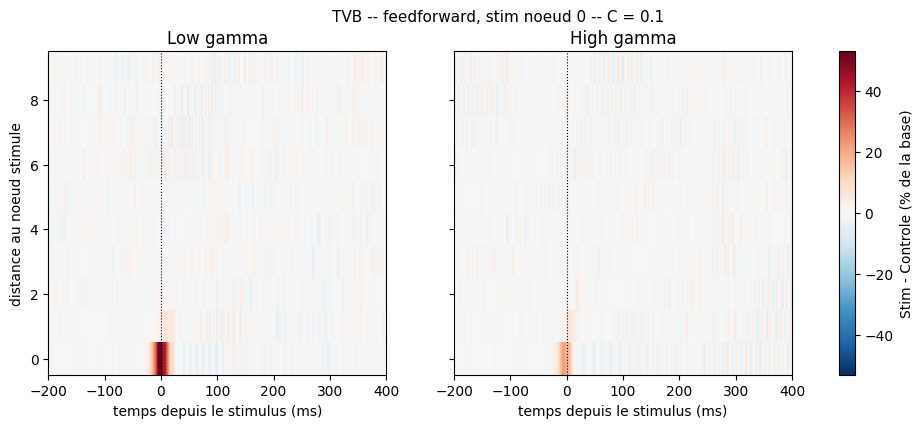

figure: figures_gamma\02\TVB_PCT_TEMPS_DISTANCE_ff_stim0_C0.1.png


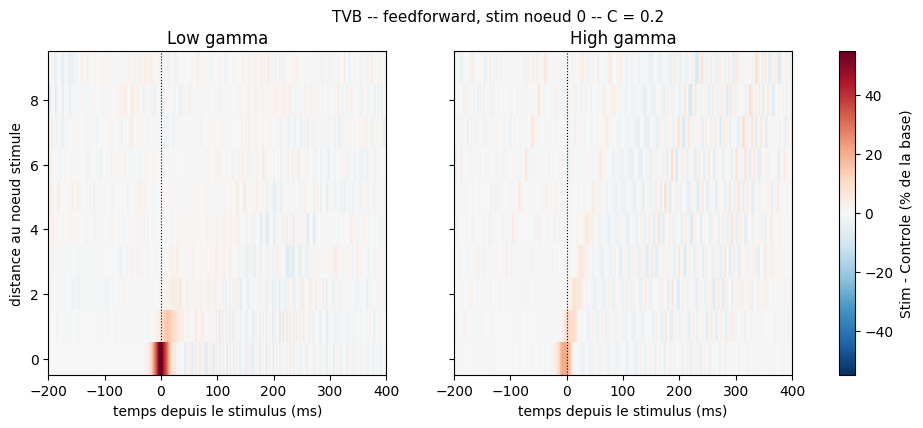

figure: figures_gamma\02\TVB_PCT_TEMPS_DISTANCE_ff_stim0_C0.2.png


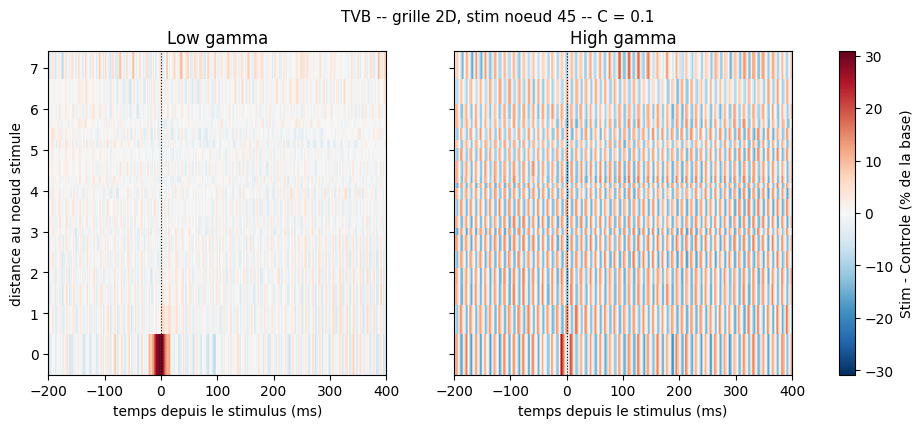

figure: figures_gamma\02\TVB_PCT_TEMPS_DISTANCE_grille_stim45_C0.1.png


In [25]:
for (geo, stim) in CAS_TVB:
    for A in (0.1, 0.2):
        dispo = [l for l in ETATS_TVB if (geo, stim, A, l) in RES_TVB]
        if not dispo:
            continue
        fig, axs = plt.subplots(1, len(dispo), figsize=(6*len(dispo), 4.2), sharey=True, squeeze=False)
        cartes = {l: profil(stim_moins_ctl_pct(RES_TVB[(geo, stim, A, l)])[0], geo, stim) for l in dispo}
        vmax = max(np.abs(M).max() for _, M in cartes.values())
        for ax, lab in zip(axs[0], dispo):
            ud, M = cartes[lab]
            im = ax.pcolormesh(RES_TVB[(geo, stim, A, lab)]["t_ms"], ud, M.T, cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="nearest")
            ax.axvline(0, color="k", ls=":", lw=0.8); ax.set_xlim(-200, 400)
            ax.set_title(lab + ("  (sature)" if sature(RES_TVB[(geo, stim, A, lab)]) else ""))
            ax.set_xlabel("temps depuis le stimulus (ms)")
        axs[0][0].set_ylabel("distance au noeud stimule")
        fig.colorbar(im, ax=axs[0].tolist(), label="Stim - Controle (% de la base)")
        fig.suptitle("TVB %s-- %s, stim noeud %d -- C = %g" % (TAG_TVB.replace("_", " "), NOMS[geo], stim, A), fontsize=11)
        fp = os.path.join(FIGDIR, "TVB_%sPCT_TEMPS_DISTANCE_%s_stim%d_C%g.png" % (TAG_TVB, geo, stim, A))
        plt.savefig(fp, dpi=150, bbox_inches="tight"); plt.show(); print("figure: " + fp)

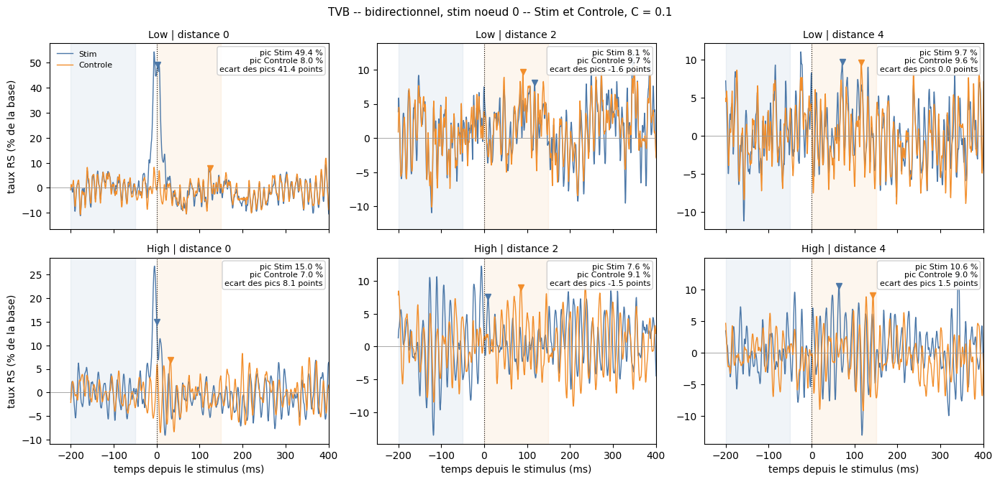

figure: figures_gamma\02\TVB_PCT_TRACES_bidir_stim0_C0.1.png


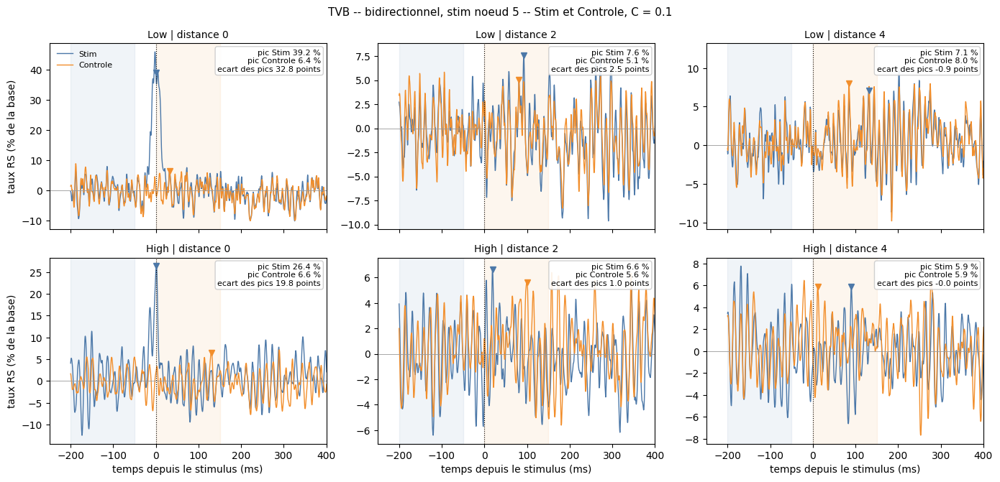

figure: figures_gamma\02\TVB_PCT_TRACES_bidir_stim5_C0.1.png


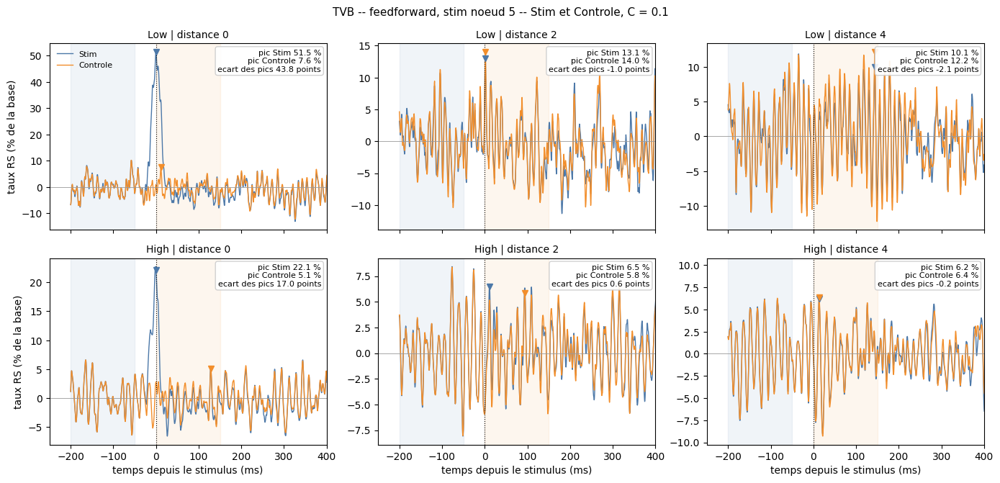

figure: figures_gamma\02\TVB_PCT_TRACES_ff_stim5_C0.1.png


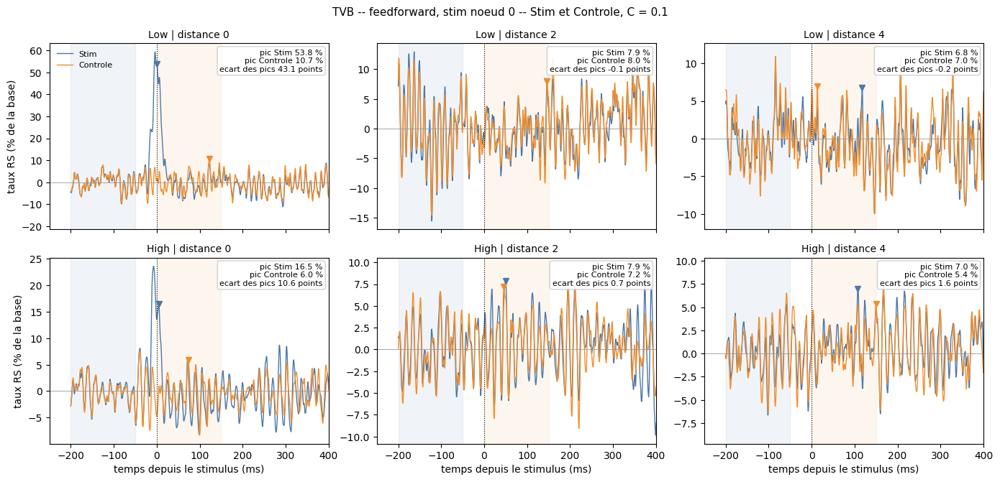

figure: figures_gamma\02\TVB_PCT_TRACES_ff_stim0_C0.1.png


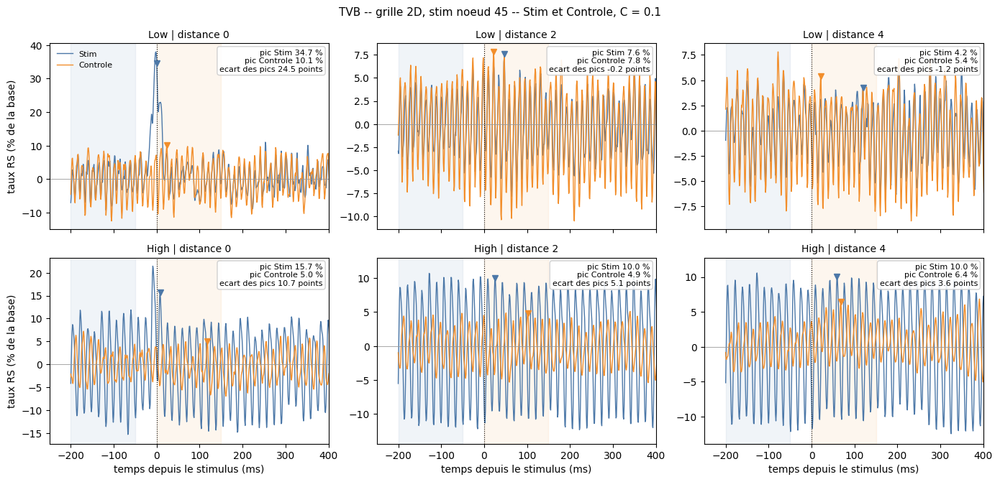

figure: figures_gamma\02\TVB_PCT_TRACES_grille_stim45_C0.1.png


In [26]:
for (geo, stim) in CAS_TVB:
    dispo = [l for l in ETATS_TVB if (geo, stim, C_TRACE, l) in RES_TVB]
    if not dispo:
        continue
    fig, axs = plt.subplots(len(dispo), 3, figsize=(14, 3.4*len(dispo)), sharex=True, squeeze=False)
    for row, lab in enumerate(dispo):
        r = RES_TVB[(geo, stim, C_TRACE, lab)]
        t = r["t_ms"]; _, fen = masques(t)
        ud, Ms = profil(r["rs_m"], geo, stim); _, Mc = profil(r["ctl_m"], geo, stim)
        Ps, Pc = en_pct(Ms, t), en_pct(Mc, t)
        for col, dd in enumerate((0, 2, 4)):
            ax = axs[row, col]
            if dd not in ud:
                ax.axis("off"); continue
            k = list(ud).index(dd)
            ax.plot(t, Ps[:, k], lw=1, color="#4C78A8", label="Stim")
            ax.plot(t, Pc[:, k], lw=1, color="#F28E2B", label="Controle")
            ax.axvspan(*PRE_MS, color="#4C78A8", alpha=0.08); ax.axvspan(*FEN_MS, color="#F28E2B", alpha=0.08)
            ax.axvline(0, color="k", ls=":", lw=0.8); ax.axhline(0, color="0.6", lw=0.6)
            ps, pc = Ps[fen, k].max(), Pc[fen, k].max()
            ax.plot(t[fen][Ps[fen, k].argmax()], ps, "v", color="#4C78A8", ms=6)
            ax.plot(t[fen][Pc[fen, k].argmax()], pc, "v", color="#F28E2B", ms=6)
            ax.text(0.98, 0.97, "pic Stim %.1f %%\npic Controle %.1f %%\necart des pics %.1f points"
                    % (ps, pc, ps - pc), transform=ax.transAxes, ha="right", va="top", fontsize=8,
                    bbox=dict(boxstyle="round", fc="white", ec="0.8", alpha=0.9))
            ax.set_xlim(-250, 400); ax.set_title("%s | distance %d" % (lab.split()[0], dd), fontsize=10)
            if col == 0: ax.set_ylabel("taux RS (% de la base)")
            if row == 0 and col == 0: ax.legend(fontsize=8, frameon=False, loc="upper left")
    for ax in axs[-1]: ax.set_xlabel("temps depuis le stimulus (ms)")
    fig.suptitle("TVB %s-- %s, stim noeud %d -- Stim et Controle, C = %g" % (TAG_TVB.replace("_", " "), NOMS[geo], stim, C_TRACE), fontsize=11)
    plt.tight_layout()
    fp = os.path.join(FIGDIR, "TVB_%sPCT_TRACES_%s_stim%d_C%g.png" % (TAG_TVB, geo, stim, C_TRACE))
    plt.savefig(fp, dpi=150, bbox_inches="tight"); plt.show(); print("figure: " + fp)

In [27]:
for (geo, stim) in CAS_TVB:
    print("\n%s, stim noeud %d" % (NOMS[geo], stim))
    print("   C     etat        d=0 Stim | Ctl     d=2 Stim | Ctl     d=4 Stim | Ctl")
    for A in C_LIST:
        for lab in ETATS_TVB:
            if (geo, stim, A, lab) not in RES_TVB:
                continue
            r = RES_TVB[(geo, stim, A, lab)]
            ud, y = profil(r["pic"], geo, stim); _, f = profil(r["plancher"], geo, stim)
            cases = ["%7.1f | %5.1f" % (y[list(ud).index(dd)], f[list(ud).index(dd)]) if dd in ud else "      -        " for dd in (0, 2, 4)]
            print("  %-5g %-10s %s%s" % (A, lab, "   ".join(cases), "   (sature)" if sature(r) else ""))


bidirectionnel, stim noeud 0
   C     etat        d=0 Stim | Ctl     d=2 Stim | Ctl     d=4 Stim | Ctl
  0.01  Low gamma     52.4 |   8.3      11.1 |  10.9       5.3 |   5.3
  0.01  High gamma    22.2 |   7.0       8.6 |   9.3       6.6 |   6.5
  0.05  Low gamma     51.7 |  11.2       9.5 |   9.0       7.1 |   7.0
  0.05  High gamma    24.0 |   6.6       8.2 |   7.5       7.4 |   7.2
  0.1   Low gamma     49.4 |   8.0       8.1 |   9.7       9.7 |   9.6
  0.1   High gamma    15.0 |   7.0       7.6 |   9.1      10.6 |   9.0
  0.2   Low gamma     34.4 |  12.6      13.8 |  13.3      12.9 |  12.7
  0.2   High gamma     8.6 |  38.7       6.2 |  24.2       5.3 |  12.2
  0.3   Low gamma      0.3 |   0.0       0.0 |   0.0       0.0 |   0.0   (sature)
  0.3   High gamma     0.2 |   0.0       0.0 |   0.0       0.0 |   0.0   (sature)
  0.4   Low gamma      0.0 |   0.0       0.0 |   0.0       0.0 |   0.0   (sature)
  0.4   High gamma     0.0 |   0.0       0.0 |   0.0       0.0 |   0.0   (sature)


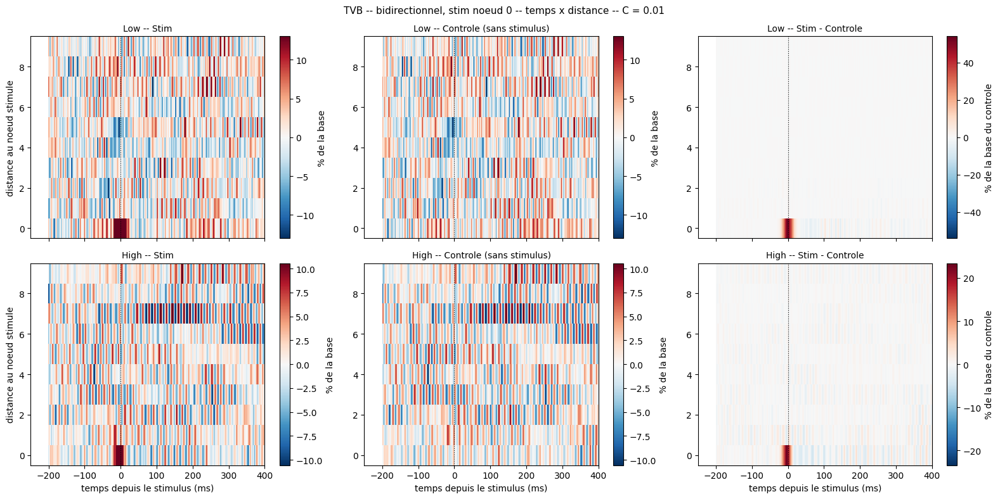

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_bidir_stim0_C0.01.png


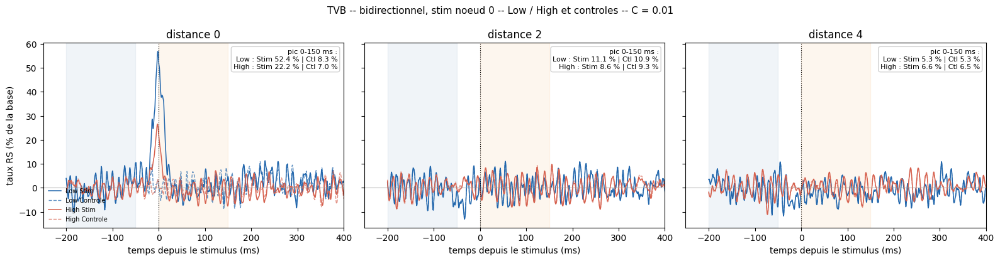

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_bidir_stim0_C0.01.png


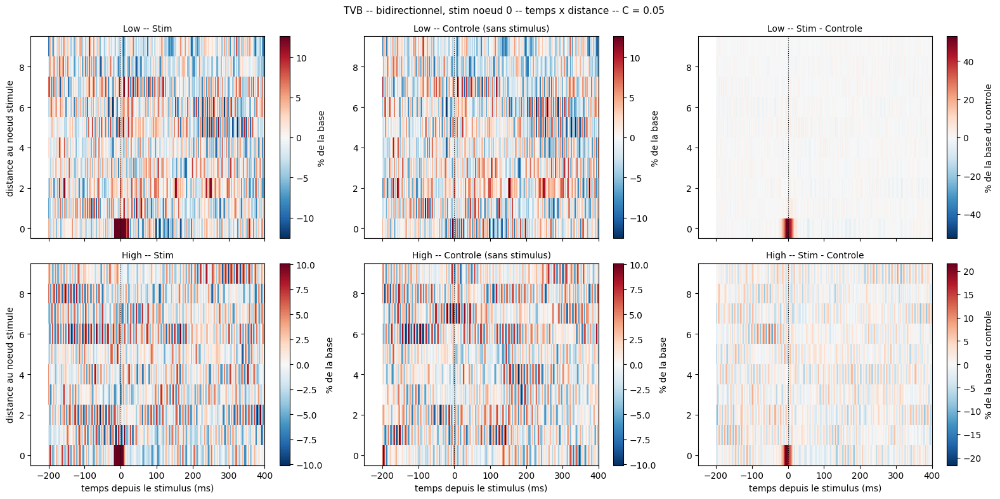

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_bidir_stim0_C0.05.png


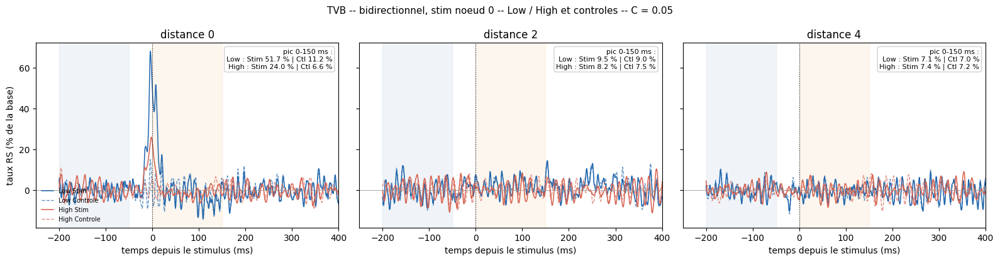

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_bidir_stim0_C0.05.png


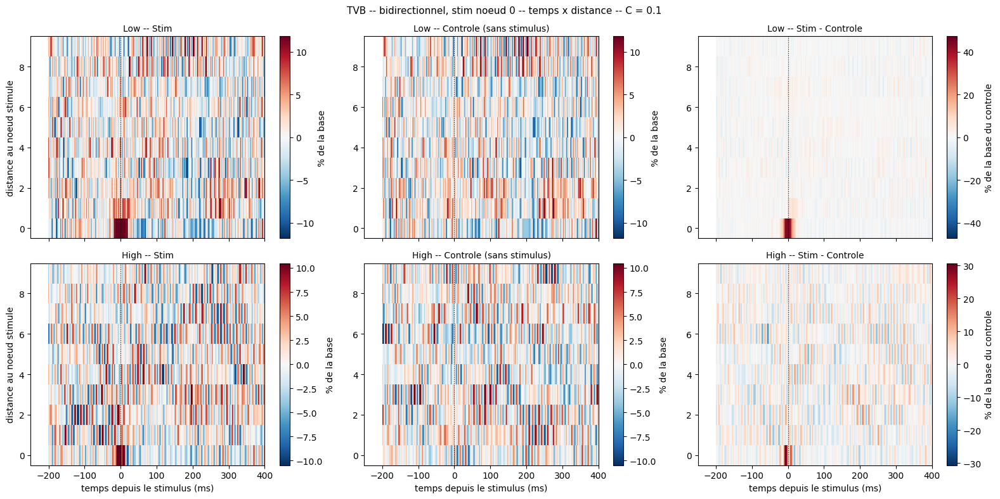

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_bidir_stim0_C0.1.png


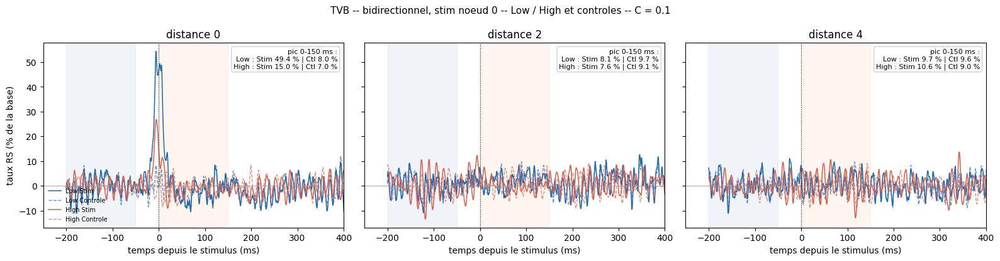

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_bidir_stim0_C0.1.png


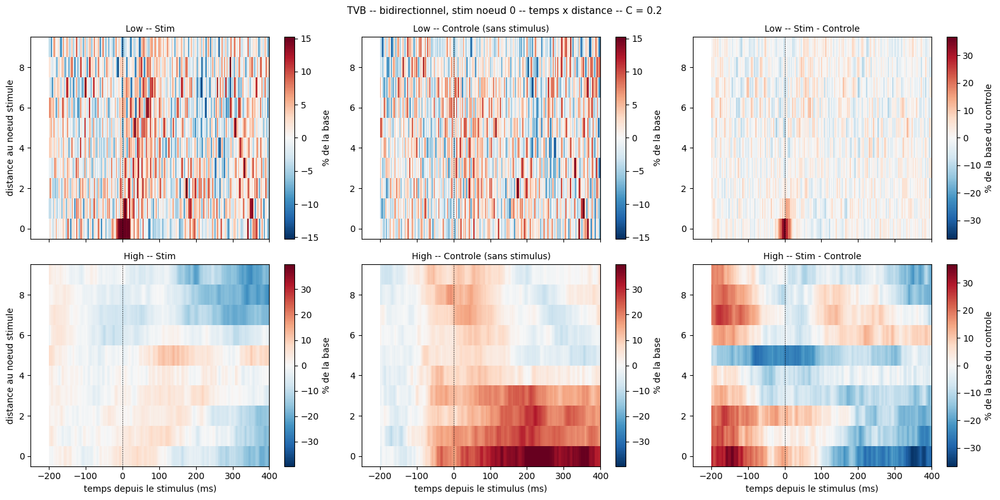

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_bidir_stim0_C0.2.png


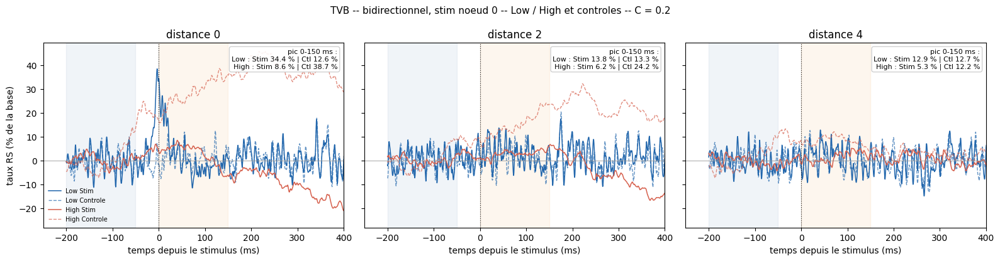

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_bidir_stim0_C0.2.png


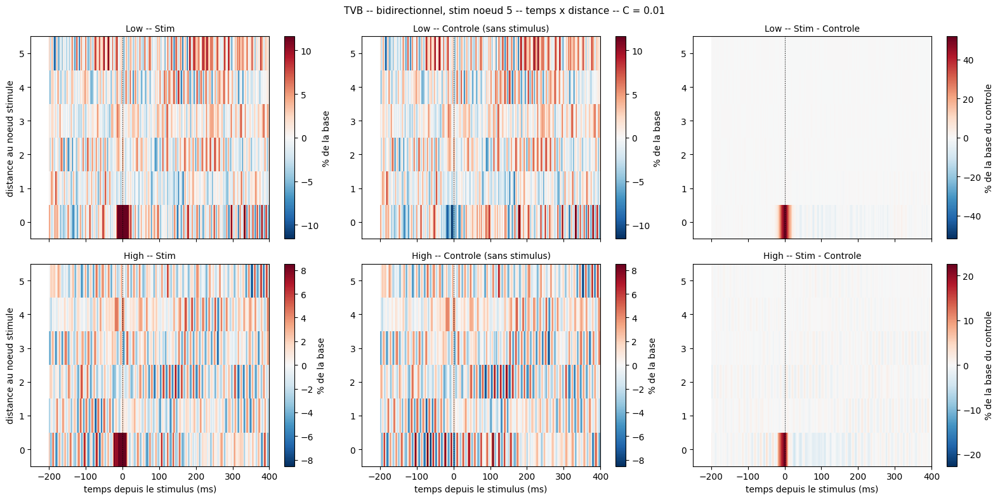

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_bidir_stim5_C0.01.png


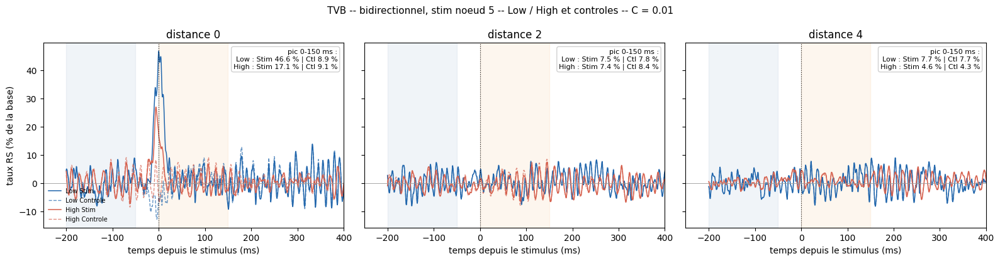

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_bidir_stim5_C0.01.png


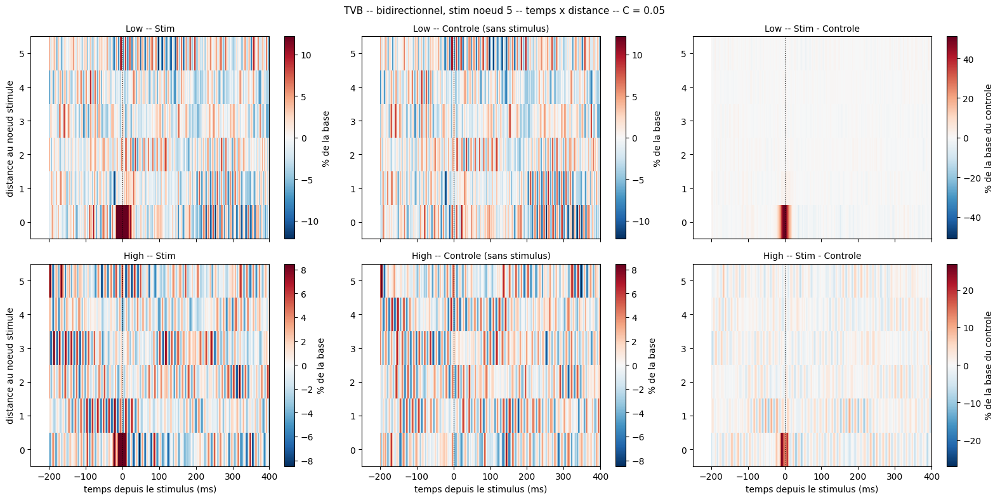

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_bidir_stim5_C0.05.png


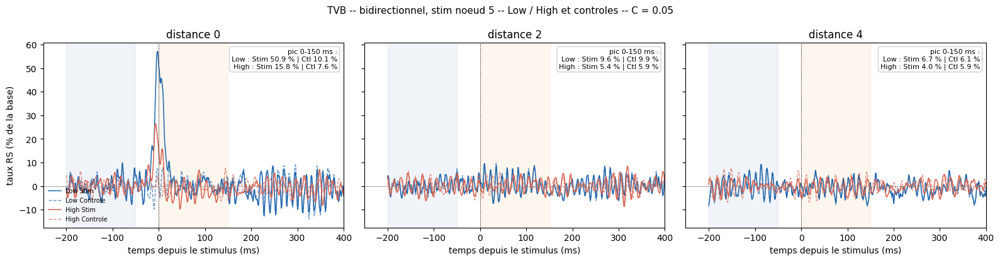

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_bidir_stim5_C0.05.png


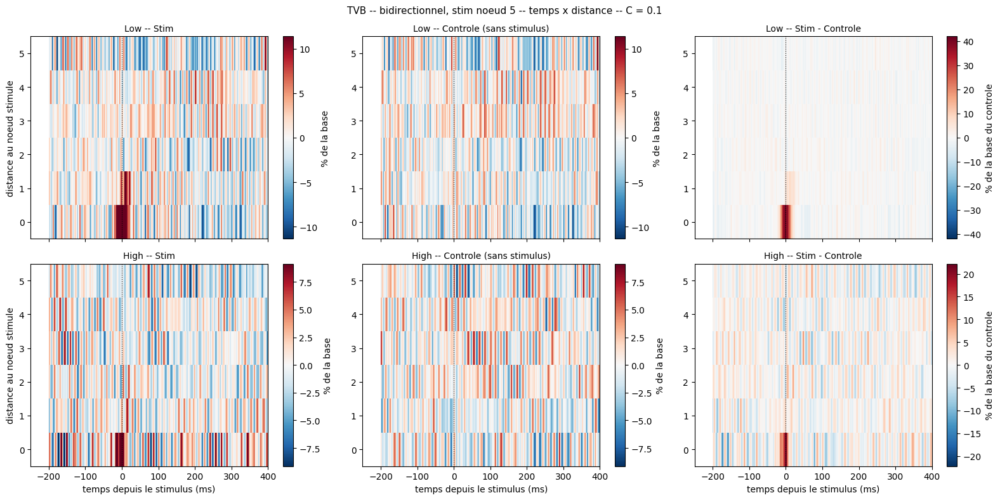

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_bidir_stim5_C0.1.png


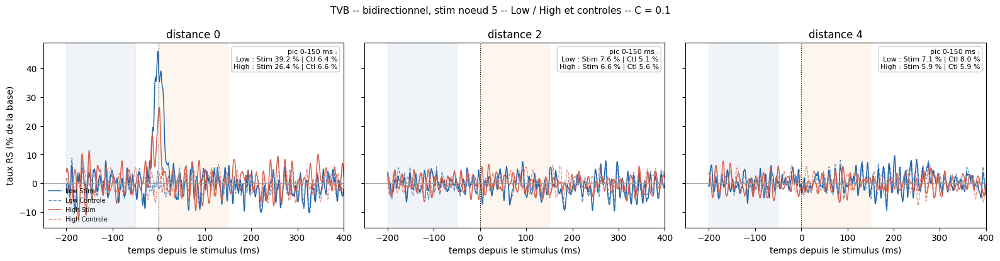

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_bidir_stim5_C0.1.png


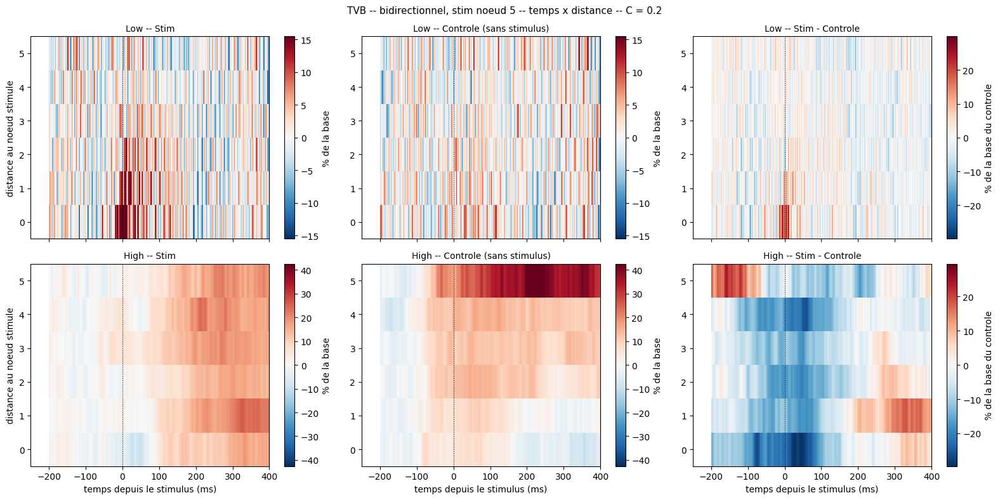

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_bidir_stim5_C0.2.png


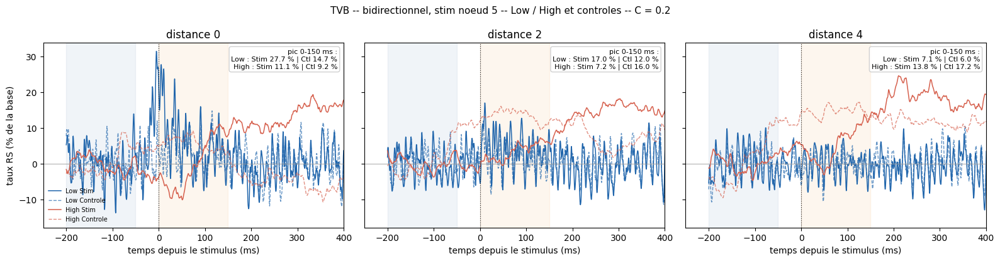

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_bidir_stim5_C0.2.png


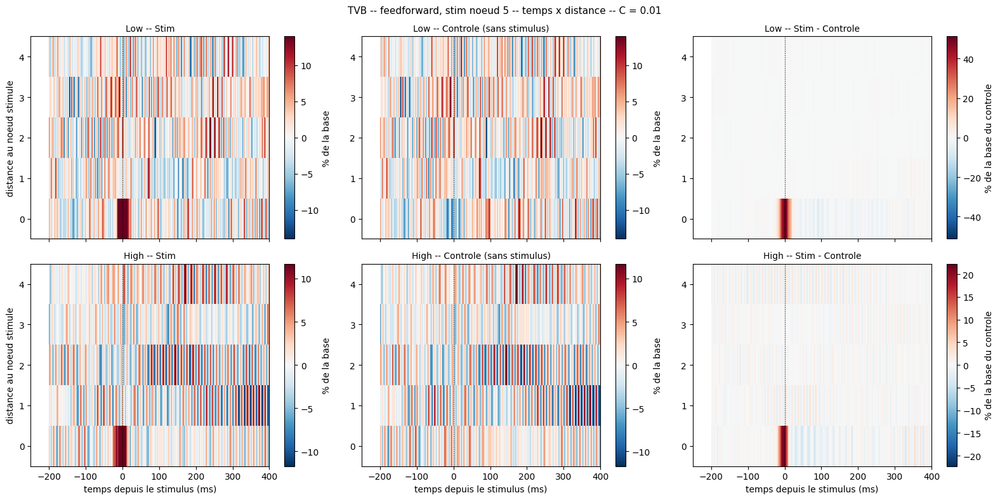

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_ff_stim5_C0.01.png


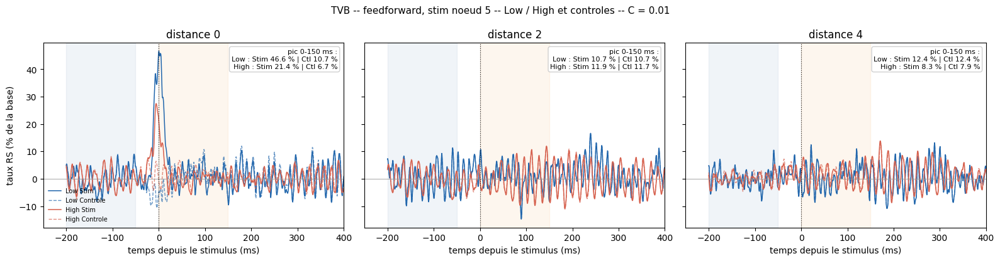

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_ff_stim5_C0.01.png


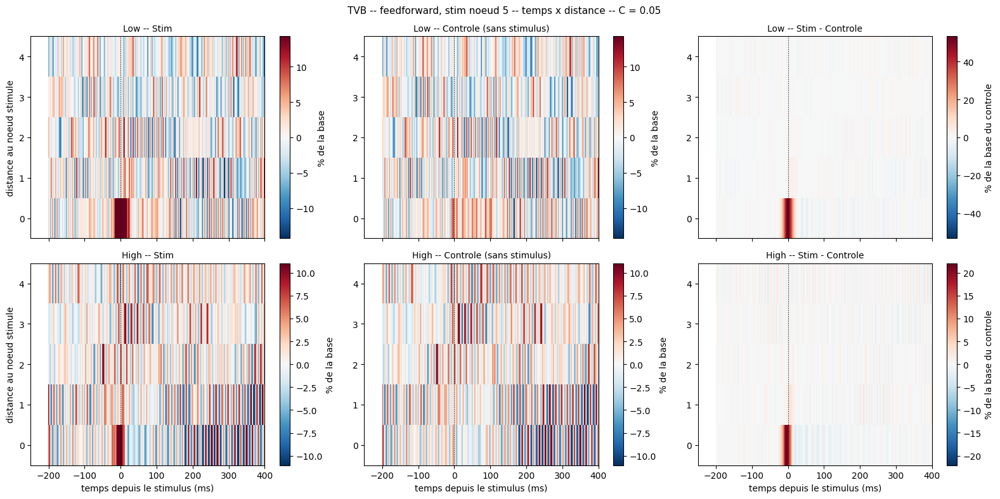

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_ff_stim5_C0.05.png


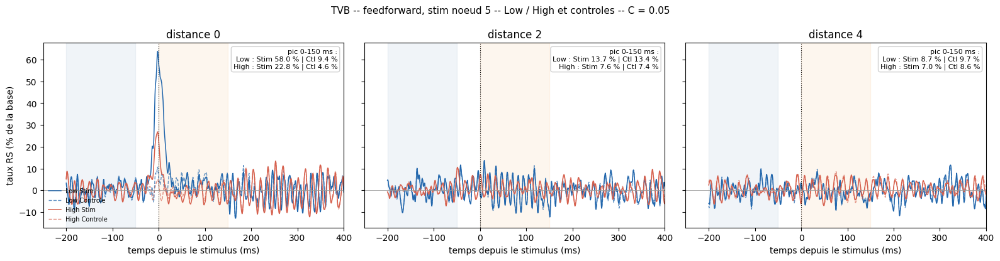

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_ff_stim5_C0.05.png


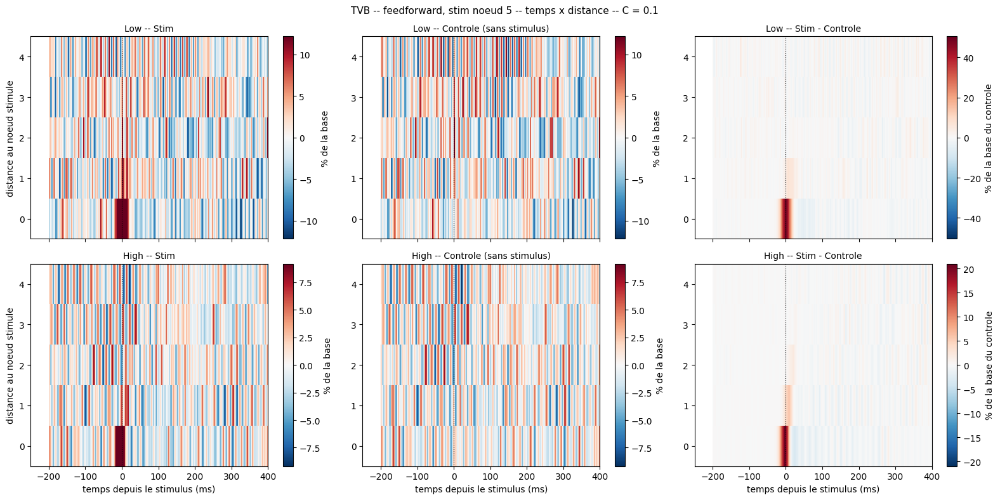

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_ff_stim5_C0.1.png


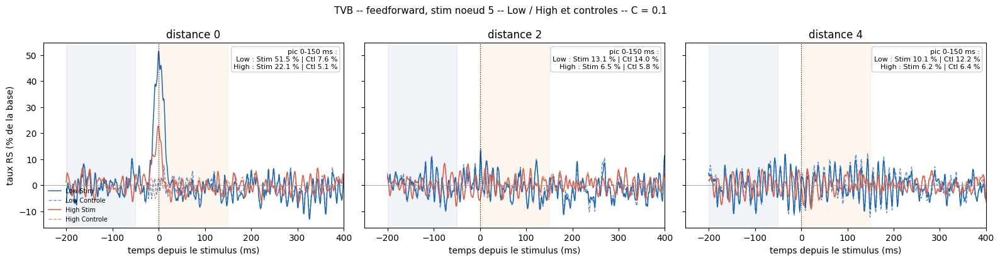

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_ff_stim5_C0.1.png


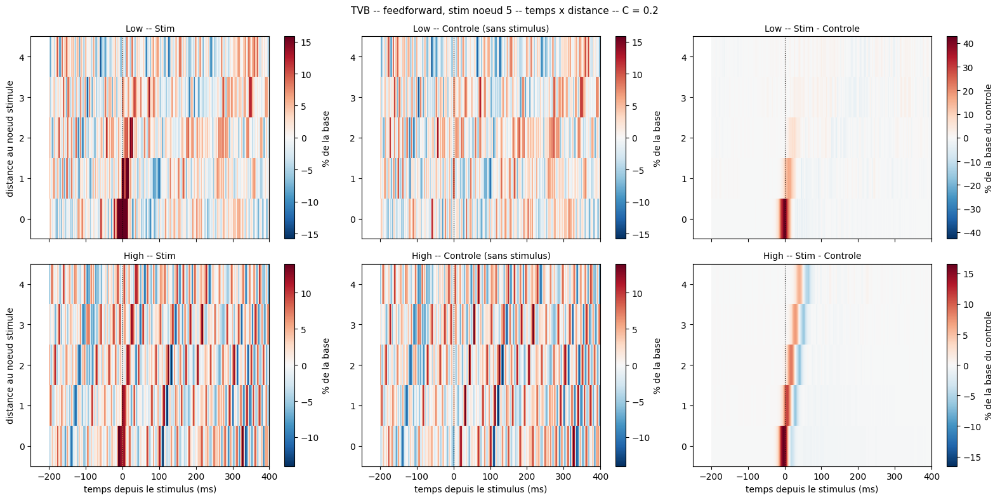

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_ff_stim5_C0.2.png


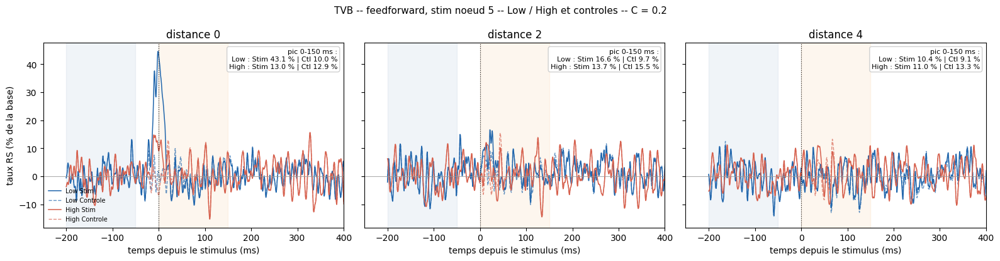

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_ff_stim5_C0.2.png


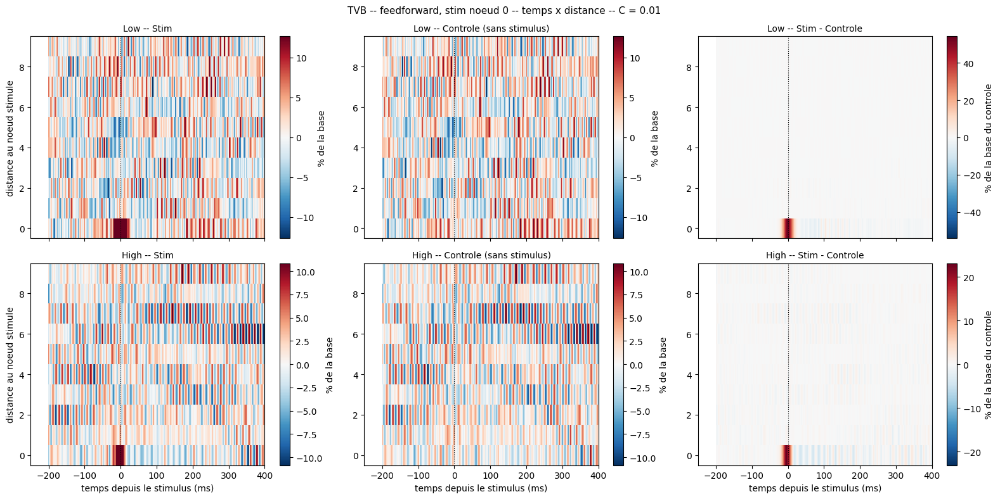

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_ff_stim0_C0.01.png


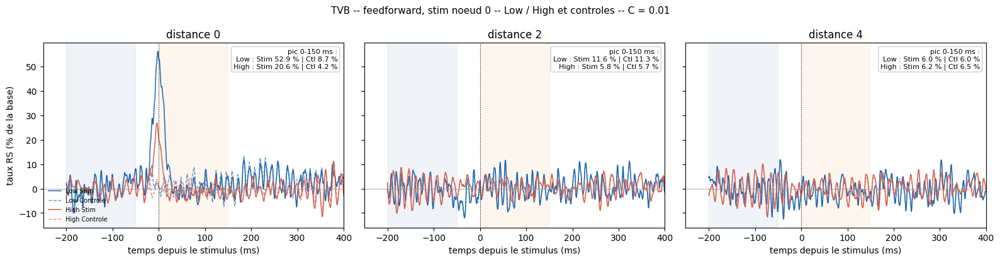

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_ff_stim0_C0.01.png


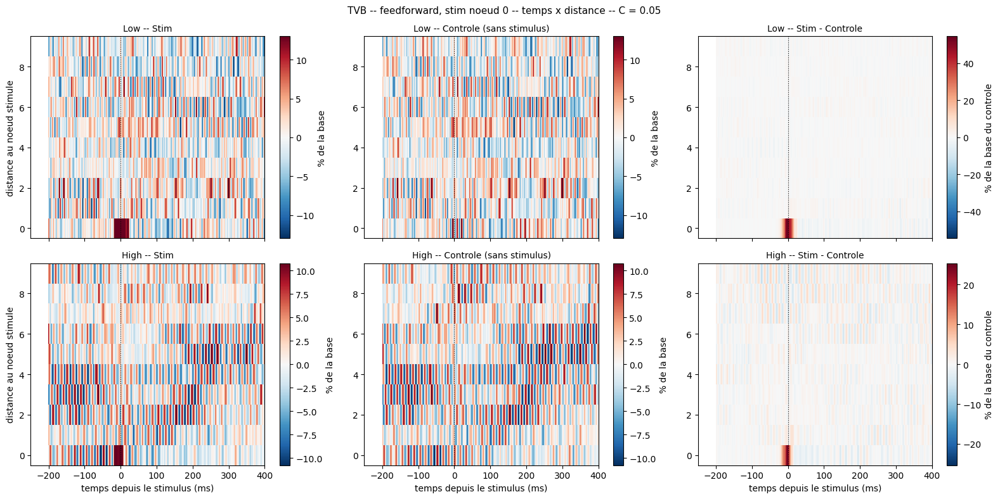

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_ff_stim0_C0.05.png


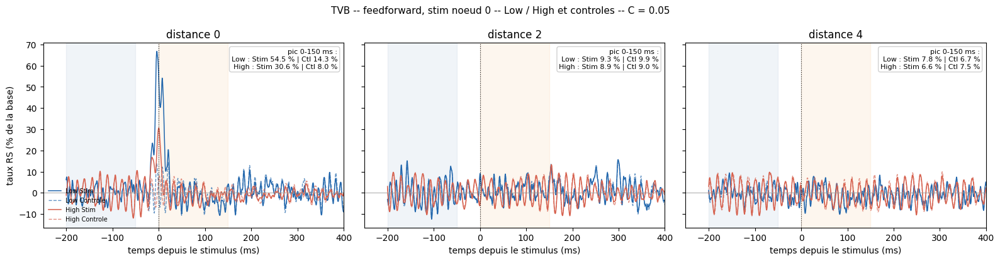

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_ff_stim0_C0.05.png


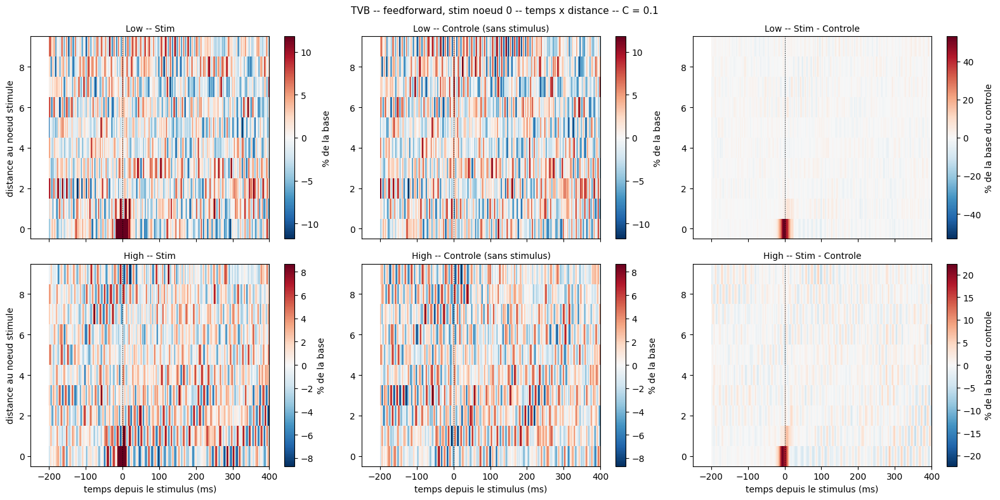

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_ff_stim0_C0.1.png


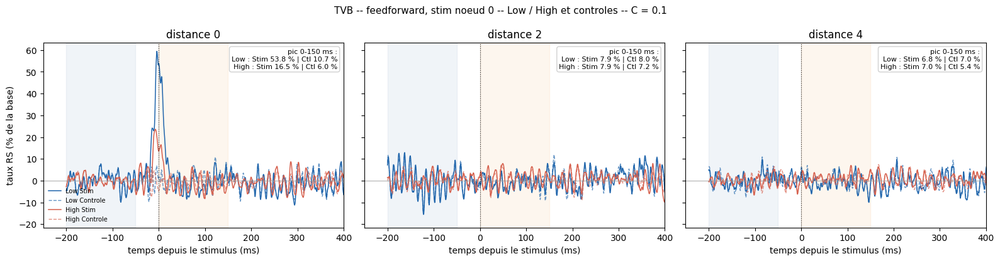

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_ff_stim0_C0.1.png


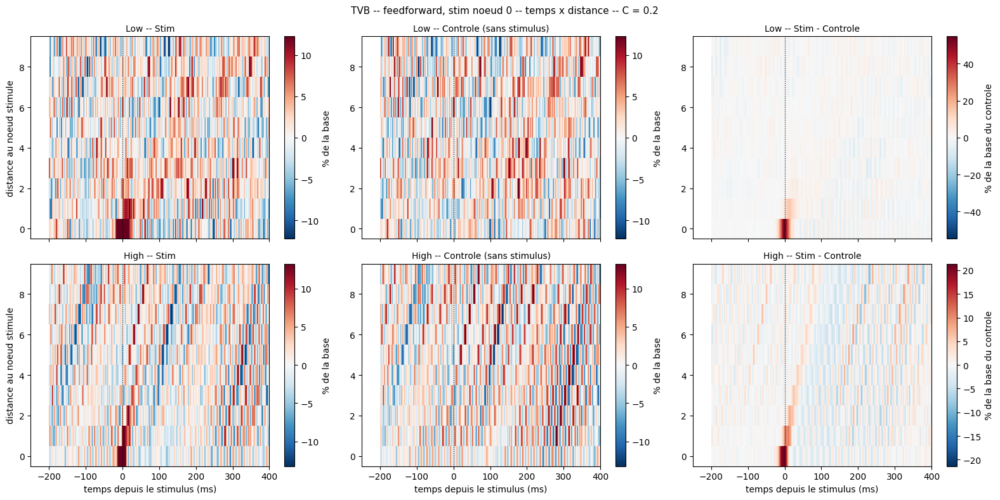

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_ff_stim0_C0.2.png


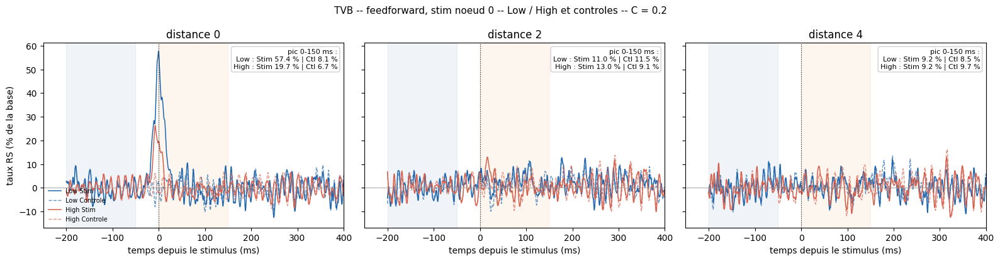

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_ff_stim0_C0.2.png


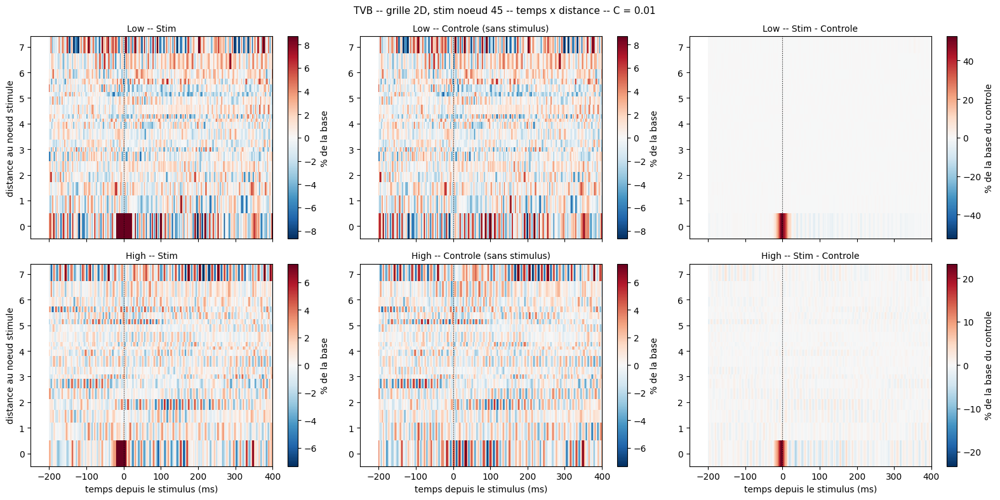

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_grille_stim45_C0.01.png


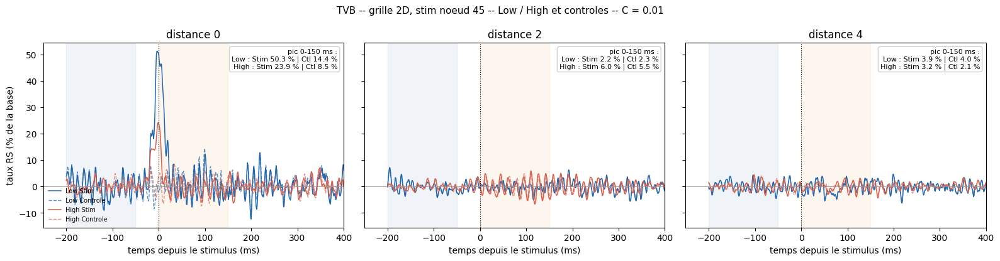

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_grille_stim45_C0.01.png


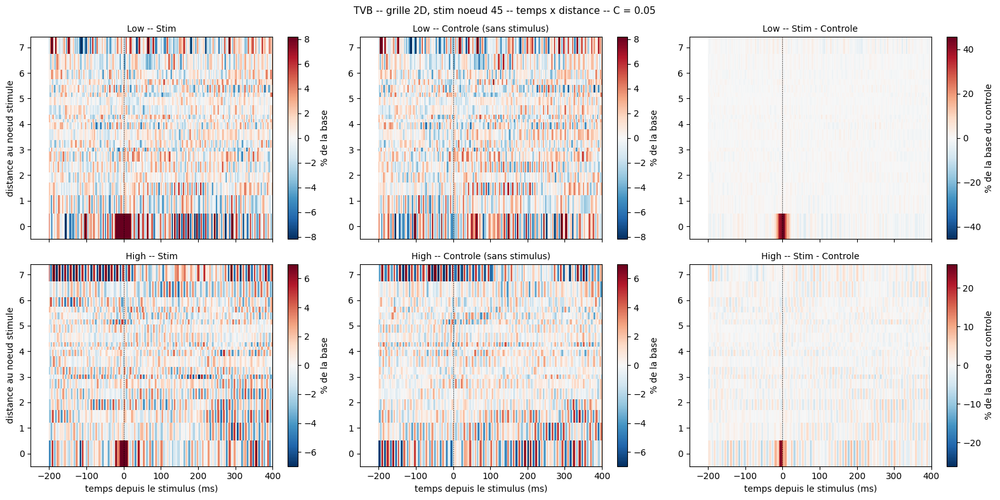

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_grille_stim45_C0.05.png


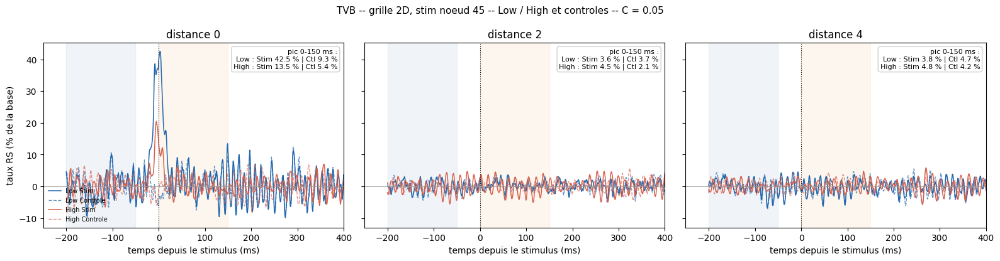

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_grille_stim45_C0.05.png


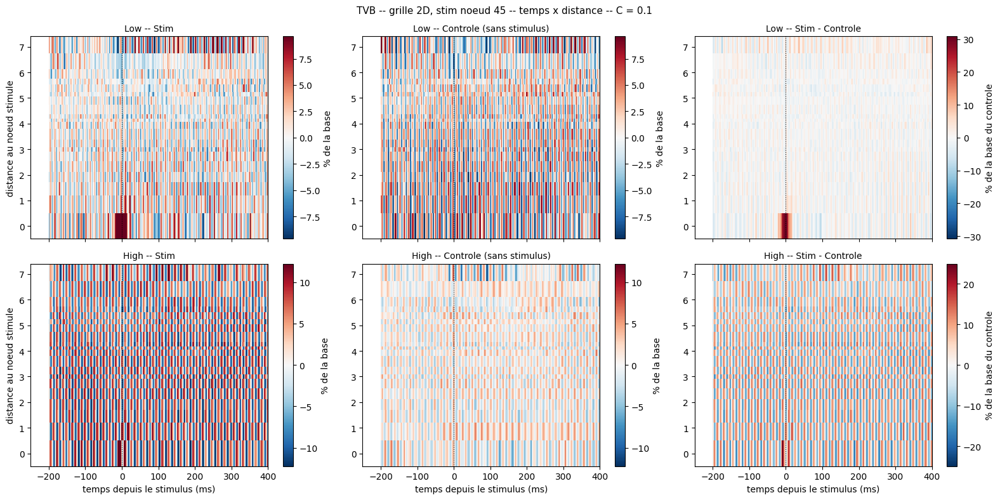

figure: figures_gamma\02\TVB_PCT_TIMEDIST_ALL_grille_stim45_C0.1.png


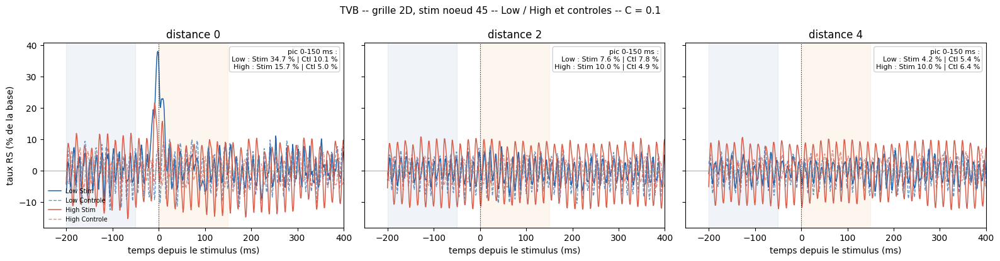

figure: figures_gamma\02\TVB_PCT_ALL_TRACES_grille_stim45_C0.1.png


In [28]:
RES, ETATS, COLS, CAS, NOMSD, LISTE_C = RES_TVB, list(ETATS_TVB), COL_TVB, CAS_TVB, NOMS, C_LIST
TITRE = "TVB %s-- " % TAG_TVB.replace("_", " ")
TEMPS = lambda r: r["t_ms"]
def FICHIER(fig, nom):
    fp = os.path.join(FIGDIR, "TVB_%sPCT_%s.png" % (TAG_TVB, nom))
    fig.savefig(fp, dpi=110, bbox_inches="tight"); plt.show(); print("figure: " + fp)


C_ZIP = [A for A in LISTE_C if A <= 0.2]
for (geo, stim) in CAS:
    for A in C_ZIP:
        dispo = [l for l in ETATS if (geo, stim, A, l) in RES]
        if not dispo:
            continue
        # --- temps x distance
        fig, axs = plt.subplots(len(dispo), 3, figsize=(16, 4.0*len(dispo)), sharex=True, squeeze=False)
        for row, lab in enumerate(dispo):
            r = RES[(geo, stim, A, lab)]; t = TEMPS(r)
            ud, Ms = profil(r["rs_m"], geo, stim); _, Mc = profil(r["ctl_m"], geo, stim)
            Ps, Pc = en_pct(Ms, t), en_pct(Mc, t)
            _, Pd = profil(stim_moins_ctl_pct(r)[0], geo, stim)
            v = max(np.percentile(np.abs(np.concatenate([Ps.ravel(), Pc.ravel()])), 99.5), 1e-9)
            vd = max(np.abs(Pd).max(), 1e-9)
            for col, (M, titre, lim, cb) in enumerate([(Ps, "Stim", v, "% de la base"), (Pc, "Controle (sans stimulus)", v, "% de la base"),
                                                      (Pd, "Stim - Controle", vd, "% de la base du controle")]):
                ax = axs[row, col]
                im = ax.pcolormesh(t, ud, M.T, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="nearest")
                ax.axvline(0, color="k", ls=":", lw=0.8); ax.set_xlim(-250, 400)
                ax.set_title("%s -- %s%s" % (lab.split()[0], titre, "  (sature)" if sature(r) else ""), fontsize=10)
                fig.colorbar(im, ax=ax, label=cb)
                if col == 0: ax.set_ylabel("distance au noeud stimule")
                if row == len(dispo)-1: ax.set_xlabel("temps depuis le stimulus (ms)")
        fig.suptitle("%s%s, stim noeud %d -- temps x distance -- C = %g" % (TITRE, NOMSD[geo], stim, A), fontsize=11)
        plt.tight_layout(); FICHIER(fig, "TIMEDIST_ALL_%s_stim%d_C%g" % (geo, stim, A))

        fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
        for col, dd in enumerate((0, 2, 4)):
            ax = axs[col]; txt = []
            for lab in dispo:
                r = RES[(geo, stim, A, lab)]; t = TEMPS(r); _, fen = masques(t)
                ud, Ms = profil(r["rs_m"], geo, stim); _, Mc = profil(r["ctl_m"], geo, stim)
                if dd not in ud:
                    continue
                k = list(ud).index(dd)
                ps, pc = en_pct(Ms, t)[:, k], en_pct(Mc, t)[:, k]
                ax.plot(t, ps, "-", lw=1.1, color=COLS[lab], label=lab.split()[0] + " Stim")
                ax.plot(t, pc, "--", lw=1.0, color=COLS[lab], alpha=0.7, label=lab.split()[0] + " Controle")
                txt.append("%s : Stim %.1f %% | Ctl %.1f %%" % (lab.split()[0], ps[fen].max(), pc[fen].max()))
            ax.axvspan(*PRE_MS, color="#4C78A8", alpha=0.08); ax.axvspan(*FEN_MS, color="#F28E2B", alpha=0.08)
            ax.axvline(0, color="k", ls=":", lw=0.8); ax.axhline(0, color="0.6", lw=0.6); ax.set_xlim(-250, 400)
            ax.set_title("distance %d" % dd); ax.set_xlabel("temps depuis le stimulus (ms)")
            if txt:
                ax.text(0.98, 0.97, "pic 0-150 ms :\n" + "\n".join(txt), transform=ax.transAxes, ha="right", va="top", fontsize=8,
                        bbox=dict(boxstyle="round", fc="white", ec="0.8", alpha=0.9))
        axs[0].set_ylabel("taux RS (% de la base)"); axs[0].legend(fontsize=7, frameon=False, loc="lower left")
        fig.suptitle("%s%s, stim noeud %d -- Low / High et controles -- C = %g" % (TITRE, NOMSD[geo], stim, A), fontsize=11)
        plt.tight_layout(); FICHIER(fig, "ALL_TRACES_%s_stim%d_C%g" % (geo, stim, A))